In [46]:
from datasets import load_dataset

dataset = load_dataset("intro/flickr8k")

dataset["train"][0]

KeyboardInterrupt: 

In [ ]:
import numpy as np

In [ ]:
sample = dataset['train'][0]
random_index = np.random.randint(0,5)
print(random_index)
caption_key  = f"caption_{random_index}"
caption = sample[caption_key]
print(caption)

2
A little girl climbing into a wooden playhouse .


In [ ]:
from torch.utils.data import Dataset
from torchvision import transforms

class Flickr8kDataset(Dataset):
    def __init__(self,dataset):
        super().__init__()
        self.dataset = dataset
        self.transform = transforms.Compose([
            transforms.Resize((224,224)),
            transforms.ToTensor()
        ])
                

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        sample = self.dataset[index]
        image = sample['image']
        random_index = np.random.randint(0,5)
        caption_key  = f"caption_{random_index}"
        caption = sample[caption_key]  
        image = self.transform(image)
        return image, caption     

In [ ]:
train_dataset = Flickr8kDataset(dataset['train'])

image, caption = train_dataset[0]

print(type(image))
print(image.shape)
print(caption)

<class 'torch.Tensor'>
torch.Size([3, 224, 224])
A little girl in a pink dress going into a wooden cabin .


In [ ]:
from collections import Counter

def count_words_in_sample(sample):
    words = []

    for i in range(5):
        caption_key = f"caption_{i}"
        caption = sample[caption_key].lower()
        words.extend(caption.split())

    return Counter(words)

In [ ]:
count_words_in_sample(dataset['train'][0])

Counter({'a': 11,
         '.': 5,
         'girl': 4,
         'in': 3,
         'climbing': 3,
         'into': 3,
         'wooden': 3,
         'little': 3,
         'pink': 2,
         'dress': 2,
         'stairs': 2,
         'going': 2,
         'playhouse': 2,
         'child': 1,
         'is': 1,
         'up': 1,
         'set': 1,
         'of': 1,
         'an': 1,
         'entry': 1,
         'way': 1,
         'building': 1,
         'the': 1,
         'to': 1,
         'her': 1,
         'cabin': 1})

In [ ]:
word_counts = Counter()
for sample in dataset['train']:
    
    words = count_words_in_sample(sample)
    word_counts.update(words)

print(word_counts.most_common(20))
print(len(word_counts))

[('a', 46781), ('.', 27162), ('in', 14085), ('the', 13509), ('on', 8006), ('is', 6907), ('and', 6672), ('dog', 6159), ('with', 5763), ('man', 5374), ('of', 4967), ('two', 4246), ('white', 2921), ('black', 2854), ('boy', 2634), ('are', 2619), ('woman', 2543), ('girl', 2414), (',', 2409), ('to', 2303)]
7705


In [ ]:
freq_1 = sum(1 for count in word_counts.values() if count == 1)
freq_2_or_less = sum(1 for count in word_counts.values() if count <= 2)
freq_5_or_less = sum(1 for count in word_counts.values() if count <= 5)

print(freq_1)
print(freq_2_or_less)
print(freq_5_or_less)

3188
4211
5429


In [ ]:
def get_word_id(word_counts):
    word_to_id = {}
    word_to_id['<PAD>'] = 0
    word_to_id['<UNK>'] = 1
    for word, count in word_counts.items():
        if count >= 2:
            word_to_id[word] = len(word_to_id)
        
    return word_to_id

def get_id_word(word_to_id):
    id_to_word = {id: word for word, id in word_to_id.items()}
    return id_to_word



word_to_id = get_word_id(word_counts)
id_to_word = get_id_word(word_to_id)

print(len(word_to_id))
print(list(word_to_id.items())[:20])

4519
[('<PAD>', 0), ('<UNK>', 1), ('a', 2), ('child', 3), ('in', 4), ('pink', 5), ('dress', 6), ('is', 7), ('climbing', 8), ('up', 9), ('set', 10), ('of', 11), ('stairs', 12), ('an', 13), ('way', 14), ('.', 15), ('girl', 16), ('going', 17), ('into', 18), ('wooden', 19)]


In [132]:
def encode_caption(caption, word_to_id):
    caption_words = caption.lower().split()
    words_to_ids = []

    for word in caption_words:
        word_id = word_to_id.get(word, word_to_id["<UNK>"])
        words_to_ids.append(word_id)

    return words_to_ids


caption = dataset["train"][0]["caption_1"]

print(caption)
print(encode_caption(caption, word_to_id))


A girl going into a wooden building .
[2, 16, 17, 18, 2, 19, 20, 15]


In [ ]:
def pad_or_truncate(ids, max_length, pad_id=0):
    if len(ids) < max_length :
        while len(ids) < max_length :
            ids.append(pad_id)
    elif len(ids) > max_length :
        while len(ids) > max_length :
            ids.pop()

    return ids


ids = [2, 16, 17, 18]
print(pad_or_truncate(ids, 8))

[2, 16, 17, 18, 0, 0, 0, 0]


In [ ]:
def create_attention_mask(ids, pad_id=0):
    attention_mask = [1 if id != pad_id else 0 for id in ids]
    return attention_mask

# Update Flick8kDataset

In [ ]:
import torch
from torch.utils.data import Dataset
from torchvision import transforms

In [137]:
class Flickr8kDataset(Dataset):
    def __init__(self, dataset, training=True, typo_rate=0.0):
        super().__init__()

        self.dataset = dataset
        self.training_mode = training
        self.typo_rate = typo_rate

        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        sample = self.dataset[index]

        image = sample["image"]

        random_index = np.random.randint(0, 5) if self.training_mode else 0
        caption_key = f"caption_{random_index}"
        caption = sample[caption_key]

        if self.typo_rate > 0:
            caption = add_typos_to_caption(
                caption,
                self.typo_rate
            )

        encoded_caption = encode_caption(
            caption,
            word_to_id
        )

        padded_caption = pad_or_truncate(
            encoded_caption,
            32
        )

        attention_mask = create_attention_mask(
            padded_caption
        )

        padded_caption = torch.tensor(
            padded_caption,
            dtype=torch.long
        )

        attention_mask = torch.tensor(
            attention_mask,
            dtype=torch.long
        )

        image = self.transform(image)

        return image, padded_caption, attention_mask

In [ ]:
train_dataset = Flickr8kDataset(dataset['train'],training=True)

image, caption_ids, attention_mask = train_dataset[0]
print(image.shape)
print(caption_ids.shape)
print(attention_mask.shape)

torch.Size([3, 224, 224])
torch.Size([32])
torch.Size([32])


In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

images, captions, masks = next(iter(train_loader))

print(images.shape)
print(captions.shape)
print(masks.shape)

torch.Size([32, 3, 224, 224])
torch.Size([32, 32])
torch.Size([32, 32])


In [ ]:
import torch.nn as nn

In [ ]:

class OneBlockImageEncoder(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.conv = nn.Conv2d(input_dim, output_dim, kernel_size=3, stride=1, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x = self.conv(x)
        x = self.relu(x)
        x = self.pool(x)
        return x

    
class ImageEncoder(nn.Module):
    def __init__(self,input_dim=3, output_dim=32):
        super().__init__()
        self.layer = nn.ModuleList([
            OneBlockImageEncoder(input_dim, output_dim),
            OneBlockImageEncoder(output_dim, output_dim*2),
            OneBlockImageEncoder(output_dim*2, output_dim*4),
            OneBlockImageEncoder(output_dim*4,output_dim*8)])

        self.AdaptiveAvgPool2d = nn.AdaptiveAvgPool2d(output_size=(1,1))
    def forward(self, x):
        for block in self.layer:
            x = block(x)

        x = self.AdaptiveAvgPool2d(x)

        x = torch.flatten(x,start_dim=1)
        return x


encoder = ImageEncoder()
output = encoder(images)

print(images.shape)
print(output.shape)

torch.Size([32, 3, 224, 224])
torch.Size([32, 256])


In [ ]:
class TextEncoder(nn.Module):
    def __init__(self,num_embedding = 4519, embedding_dim=256,padding_idx=0):
        super().__init__()
        self.Embedding = nn.Embedding(
            num_embedding,
            embedding_dim,
            padding_idx
        )

        self.positional_encoding = nn.Embedding(32, embedding_dim)
        self.TransformerEncoderLayer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=4,
            dim_feedforward=1024,
            batch_first=True
        )
        self.Transformer_encoder = nn.TransformerEncoder(
            encoder_layer=self.TransformerEncoderLayer,
            num_layers=2
        )

    def forward(self,x,attention_mask):
        positions = torch.arange(x.shape[1],device=x.device)
        token_embedded = self.Embedding(x)
        position_embedded = self.positional_encoding(positions)
        embedded = token_embedded + position_embedded
        src_key_padding_mask = attention_mask == 0
        transform = self.Transformer_encoder(embedded, src_key_padding_mask=src_key_padding_mask)
        attention_mask =  attention_mask[:,:,None]
        transform = transform * attention_mask
        result = transform.sum(dim=1) / attention_mask.sum(dim=1)


        return result


text_encoder = TextEncoder()
text_output = text_encoder(captions, masks)
print(captions.shape)
print(text_output.shape)

torch.Size([32, 32])
torch.Size([32, 256])


In [ ]:
class ProjectionImage(nn.Module):
    def __init__(self,feat_dim,emd_dim):
        super().__init__()
        self.Linear = nn.Linear(feat_dim,emd_dim)

    def forward(self,images_features):
        images_embed = self.Linear(images_features)
        
        images_norm = torch.nn.functional.normalize(images_embed)
        
        return images_norm

class ProjectionText(nn.Module):
    def __init__(self,feat_dim,emd_dim):
        super().__init__()
        self.Linear = nn.Linear(feat_dim,emd_dim)

    def forward(self,texts_features):
        texts_embed = self.Linear(texts_features)
        texts_norm = torch.nn.functional.normalize(texts_embed)

        return texts_norm

        
def similarity(image,text):
    return image @ text.T


In [ ]:
class RobustCLIP(nn.Module):
    def __init__(self,feat_dim,embed_dim):
        super().__init__()
        self.image_encoder = ImageEncoder()
        self.text_encoder = TextEncoder()
        self.projection_image = ProjectionImage(feat_dim=feat_dim,emd_dim=embed_dim)
        self.projection_text = ProjectionText(feat_dim=feat_dim,emd_dim=embed_dim)
        self.logits_scale = nn.Parameter(
            torch.log(torch.tensor(1/0.07))
        )

    def forward(self,images,captions,masks):
        images_features = self.image_encoder(images)
        texts_features = self.text_encoder(captions,masks)

        image_embeddings = self.projection_image(images_features)
        text_embeddings = self.projection_text(texts_features)
        similarities = similarity(image_embeddings,text_embeddings)
        scale = torch.exp(self.logits_scale)
        logits = similarities * scale

        return logits


In [ ]:
model = RobustCLIP(feat_dim=256, embed_dim=128)

logits = model(images, captions, masks)

print(logits.shape)

torch.Size([32, 32])


In [ ]:
def contrastive_loss(logits):
    B = logits.shape[0]
    target = torch.arange(B, device=logits.device)

    loss_fn = nn.CrossEntropyLoss()

    loss_img_txt = loss_fn(logits, target)
    loss_txt_img = loss_fn(logits.T, target)

    loss = (loss_img_txt + loss_txt_img) / 2
    return loss

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = RobustCLIP(feat_dim=256, embed_dim=128).to(device)
print(device)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,)




cuda


In [ ]:
images,captions,mask = next(iter(train_loader))

images = images.to(device)
captions = captions.to(device)
masks = mask.to(device)

optimizer.zero_grad()

logits = model(images,captions, masks)
loss = contrastive_loss(logits)

loss.backward()
optimizer.step()
print(loss.item())

3.6329097747802734


In [ ]:
for epoch in range(5):
    model.train()
    total_loss = 0
    for images,captions,mask in train_loader :
        
            
        images = images.to(device)
        captions = captions.to(device)
        masks = mask.to(device)

        optimizer.zero_grad()
        logits = model(images,captions, masks)
        loss = contrastive_loss(logits)

        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    moyenne = total_loss / len(train_loader)
    print(moyenne)

3.397451117951819
3.218331498034457
3.105508899435084
3.033523180383317
2.958202169296589


In [ ]:
print(len(dataset['test']))

1000


In [ ]:
val_dataset = Flickr8kDataset(dataset['dev'],training=False)
val_loader =  DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

In [ ]:

model.eval()
total_loss = 0
for images,captions,masks in val_loader:
    with torch.no_grad() :
        images = images.to(device)
        captions = captions.to(device)
        masks = masks.to(device)
        logits = model(images,captions,masks)
        loss = contrastive_loss(logits)
        total_loss += loss.item()
average = total_loss / len(val_loader)

print(average)


/home/braincoder/asr-env/lib/python3.13/site-packages/torch/nn/modules/transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:177.)
  output = torch._nested_tensor_from_mask(


3.0170093774795532


In [ ]:
model.eval()
images_list = []
texts_list = []
for images,captions,masks in val_loader:
    with torch.no_grad() :
        images = images.to(device)
        captions = captions.to(device)
        masks = masks.to(device)
        image_features = model.image_encoder(images)
        image_embedding = model.projection_image(image_features)
        images_list.append(image_embedding)

        text_features = model.text_encoder(captions,masks)
        text_emdedding = model.projection_text(text_features)
        texts_list.append(text_emdedding)

images_list_cat = torch.cat(images_list,dim=0)
texts_list_cat = torch.cat(texts_list,dim=0)    
similarities = images_list_cat @ texts_list_cat.T
print(images_list_cat.shape)
print(texts_list_cat.shape)
print(similarities.shape) 
torch.Size([1000, 128])
torch.Size([1000, 128])
torch.Size([1000, 1000])

torch.Size([1000, 128])
torch.Size([1000, 128])
torch.Size([1000, 1000])


torch.Size([1000, 1000])

In [ ]:
def recall_at_k(similarities, k):
    _,predictions = torch.topk(similarities,dim=1,k=k)
    target = torch.arange(similarities.shape[0],device=predictions.device)[:,None]
    is_equal = (predictions == target).any(dim=1)
    is_equal_float = is_equal.float()
    is_equal_mean = torch.mean(is_equal_float)
    recall_at = is_equal_mean.item()
    return recall_at


print(recall_at_k(similarities, 1))
print(recall_at_k(similarities, 5))
print(recall_at_k(similarities, 10))

print(recall_at_k(similarities.T, 1))
print(recall_at_k(similarities.T, 5))
print(recall_at_k(similarities.T, 10))

0.007000000216066837
0.027000000700354576
0.058000002056360245
0.00800000037997961
0.027000000700354576
0.04700000211596489


In [ ]:
dict_to_save = {
    "model_state_dict":model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": 5,
    "val_loss": 3.00638647377491,
    "image_to_text": {
        "R@1": 0.009000000543892384,
        "R@5": 0.036000002175569534,
        "R@10": 0.06100000441074371

    },
    "text_to_image": {
        "R@1": 0.007000000216066837,
        "R@5": 0.036000002175569534,
        "R@10": 0.06000000238418579
    }
}

torch.save(dict_to_save, "../models/baseline_5epochs.pt")


In [ ]:
def train_model(num_epochs):
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        for images,captions,mask in train_loader :
            
                
            images = images.to(device)
            captions = captions.to(device)
            masks = mask.to(device)

            optimizer.zero_grad()
            logits = model(images,captions, masks)
            loss = contrastive_loss(logits)

            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        moyenne = total_loss / len(train_loader)
        print(moyenne)

In [ ]:
train_model(10)

2.908863181763507
2.834593913022508
2.7861402326441826


KeyboardInterrupt: 

In [ ]:

model.eval()
images_list = []
texts_list = []
for images,captions,masks in val_loader:
    with torch.no_grad() :
        images = images.to(device)
        captions = captions.to(device)
        masks = masks.to(device)
        image_features = model.image_encoder(images)
        image_embedding = model.projection_image(image_features)
        images_list.append(image_embedding)

        text_features = model.text_encoder(captions,masks)
        text_emdedding = model.projection_text(text_features)
        texts_list.append(text_emdedding)

images_list_cat = torch.cat(images_list,dim=0)
texts_list_cat = torch.cat(texts_list,dim=0)    
similarities = images_list_cat @ texts_list_cat.T

In [59]:
def eval_model():    
    model.eval()
    total_loss = 0
    for images,captions,masks in val_loader:
        with torch.no_grad() :
            images = images.to(device)
            captions = captions.to(device)
            masks = masks.to(device)
            logits = model(images,captions,masks)
            loss = contrastive_loss(logits)
            total_loss += loss.item()
    average = total_loss / len(val_loader)
    print(average)

eval_model()

2.665776379406452


In [60]:

model.eval()
images_list = []
texts_list = []
for images,captions,masks in val_loader:
    with torch.no_grad() :
        images = images.to(device)
        captions = captions.to(device)
        masks = masks.to(device)
        image_features = model.image_encoder(images)
        image_embedding = model.projection_image(image_features)
        images_list.append(image_embedding)

        text_features = model.text_encoder(captions,masks)
        text_emdedding = model.projection_text(text_features)
        texts_list.append(text_emdedding)

images_list_cat = torch.cat(images_list,dim=0)
texts_list_cat = torch.cat(texts_list,dim=0)    
similarities = images_list_cat @ texts_list_cat.T

In [61]:
print("Image → Text")
print("R@1 :", recall_at_k(similarities, 1))
print("R@5 :", recall_at_k(similarities, 5))
print("R@10:", recall_at_k(similarities, 10))

print("\nText → Image")
print("R@1 :", recall_at_k(similarities.T, 1))
print("R@5 :", recall_at_k(similarities.T, 5))
print("R@10:", recall_at_k(similarities.T, 10))

Image → Text
R@1 : 0.02800000086426735
R@5 : 0.08900000154972076
R@10: 0.15900000929832458

Text → Image
R@1 : 0.024000000208616257
R@5 : 0.10200000554323196
R@10: 0.16100001335144043


In [62]:
dict_to_save = {
    "model_state_dict":model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": 5,
    "val_loss": 2.7679684832692146,
    "image_to_text": {
        "R@1": 0.01100000087171793,
        "R@5": 0.07200000435113907,
        "R@10": 0.11400000751018524

    },
    "text_to_image": {
        "R@1": 0.018000001087784767,
        "R@5": 0.07000000029802322,
        "R@10": 0.11400000751018524
    }
}

torch.save(dict_to_save, "../models/baseline_15epochs.pt")


In [63]:
best_val_loss = 2.7679684832692146
patience = 3
checks_without_improvement = 0

train_model(num_epochs=5)

KeyboardInterrupt: 

In [64]:
def validate_model():
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for images,captions,masks in val_loader:
            images = images.to(device)
            captions = captions.to(device)
            masks = masks.to(device)
            logits = model(images,captions,masks)
            loss = contrastive_loss(logits)
            total_loss += loss.item()
    average_val_loss =total_loss / len(val_loader)
    return average_val_loss

val_loss = validate_model()
print(val_loss)
if val_loss < best_val_loss:
    best_val_loss = val_loss
    checks_without_improvement = 0
else :
    checks_without_improvement += 1

if checks_without_improvement >= patience :
    print("Early stopping")
    

2.856241136789322


In [65]:
def train_model(
    num_epochs,
    best_val_loss,
    checks_without_improvement,
    patience,
    start_epoch
):
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        for images,captions,mask in train_loader :
            
                
            images = images.to(device)
            captions = captions.to(device)
            masks = mask.to(device)

            optimizer.zero_grad()
            logits = model(images,captions, masks)
            loss = contrastive_loss(logits)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        

        moyenne = total_loss / len(train_loader)
       
        val_loss = validate_model()
        current_epoch = start_epoch + epoch + 1
        print(f"train_loss:{moyenne}|val_loss:{val_loss}|current_epoch:{current_epoch}")
        if val_loss < best_val_loss:
            
            best_val_loss = val_loss
            checks_without_improvement = 0
            dict_to_save = {
                'model_state':model.state_dict(),
                'optimizer_state_dict':optimizer.state_dict(),
                'epoch':current_epoch,
                'val_loss':val_loss,
                'checks_without_improvement':checks_without_improvement,
                'best_val_loss':best_val_loss
            }
            
            torch.save(dict_to_save,"../models/best_baseline.pt")
        else :
            checks_without_improvement += 1

        if checks_without_improvement >= patience :
            break
    return best_val_loss, checks_without_improvement
        

In [ ]:
best_val_loss, checks_without_improvement = train_model(
    start_epoch=20,
    patience=3,
    checks_without_improvement=0,
    best_val_loss=2.7213167026638985,
    num_epochs=10
)

train_loss:2.0520700945499097|val_loss:2.6797080636024475|num_epoch:10
train_loss:1.9984273682249354|val_loss:2.7251705080270767|num_epoch:10
train_loss:1.9379107343389632|val_loss:2.720953803509474|num_epoch:10
train_loss:1.8977270227797487|val_loss:2.665776379406452|num_epoch:10
train_loss:1.843030995510994|val_loss:2.8168726824223995|num_epoch:10
train_loss:1.7982632739746824|val_loss:2.7581775933504105|num_epoch:10
train_loss:1.7174855293111597|val_loss:2.746551051735878|num_epoch:10


In [66]:
checkpoint = torch.load("../models/best_baseline.pt")
print(checkpoint['epoch'])
print(checkpoint['val_loss'])

24
2.665776379406452


In [ ]:
model.load_state_dict(checkpoint['model_state'])
model.eval()

RobustCLIP(
  (image_encoder): ImageEncoder(
    (layer): ModuleList(
      (0): OneBlockImageEncoder(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (relu): ReLU()
        (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
      (1): OneBlockImageEncoder(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (relu): ReLU()
        (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
      (2): OneBlockImageEncoder(
        (conv): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (relu): ReLU()
        (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
      (3): OneBlockImageEncoder(
        (conv): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (relu): ReLU()
        (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_

In [67]:
val_loss = validate_model()
print(val_loss)


2.856241136789322


In [68]:
print("Image → Text")
print("R@1 :", recall_at_k(similarities, 1))
print("R@5 :", recall_at_k(similarities, 5))
print("R@10:", recall_at_k(similarities, 10))

print("\nText → Image")
print("R@1 :", recall_at_k(similarities.T, 1))
print("R@5 :", recall_at_k(similarities.T, 5))
print("R@10:", recall_at_k(similarities.T, 10))

Image → Text
R@1 : 0.02800000086426735
R@5 : 0.08900000154972076
R@10: 0.15900000929832458

Text → Image
R@1 : 0.024000000208616257
R@5 : 0.10200000554323196
R@10: 0.16100001335144043


In [69]:
checkpoint = torch.load("../models/best_baseline.pt")

checkpoint["dev_retrieval"] = {
    "image_to_text": {
        "R@1": 0.02800000086426735,
        "R@5": 0.08900000154972076,
        "R@10": 0.15900000929832458
    },
    "text_to_image": {
        "R@1": 0.024000000208616257,
        "R@5": 0.10200000554323196,
        "R@10": 0.16100001335144043
    }
}

torch.save(checkpoint, "../models/best_baseline.pt")

In [70]:
checkpoint = torch.load("../models/best_baseline.pt")

print(checkpoint["epoch"])
print(checkpoint["val_loss"])
print(checkpoint["dev_retrieval"])

24
2.665776379406452
{'image_to_text': {'R@1': 0.02800000086426735, 'R@5': 0.08900000154972076, 'R@10': 0.15900000929832458}, 'text_to_image': {'R@1': 0.024000000208616257, 'R@5': 0.10200000554323196, 'R@10': 0.16100001335144043}}


In [71]:
test_dataset = Flickr8kDataset(dataset['test'],training=False)
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)
print(len(test_dataset))

1000


In [72]:

model.eval()
images_list = []
texts_list = []
for images,captions,masks in test_loader:
    with torch.no_grad() :
        images = images.to(device)
        captions = captions.to(device)
        masks = masks.to(device)
        image_features = model.image_encoder(images)
        image_embedding = model.projection_image(image_features)
        images_list.append(image_embedding)

        text_features = model.text_encoder(captions,masks)
        text_emdedding = model.projection_text(text_features)
        texts_list.append(text_emdedding)

images_list_cat = torch.cat(images_list,dim=0)
texts_list_cat = torch.cat(texts_list,dim=0)    
similarities_test = images_list_cat @ texts_list_cat.T
print(similarities_test.shape)

torch.Size([1000, 1000])


In [73]:
print("Image → Text")
print("R@1 :", recall_at_k(similarities_test, 1))
print("R@5 :", recall_at_k(similarities_test, 5))
print("R@10:", recall_at_k(similarities_test, 10))

print("\nText → Image")
print("R@1 :", recall_at_k(similarities_test.T, 1))
print("R@5 :", recall_at_k(similarities_test.T, 5))
print("R@10:", recall_at_k(similarities_test.T, 10))

Image → Text
R@1 : 0.01900000125169754
R@5 : 0.06300000101327896
R@10: 0.1120000034570694

Text → Image
R@1 : 0.024000000208616257
R@5 : 0.0820000022649765
R@10: 0.14400000870227814


In [74]:
import json
import os

results = {
    "best_epoch": 24,
    "dev_val_loss": 2.665776379406452,

    "dev_retrieval": {
        "image_to_text": {
            "R@1": 0.02800000086426735,
            "R@5": 0.08900000154972076,
            "R@10": 0.15900000929832458
        },
        "text_to_image": {
            "R@1": 0.024000000208616257,
            "R@5": 0.10200000554323196,
            "R@10": 0.16100001335144043
        }
    },

    "test_retrieval": {
        "image_to_text": {
            "R@1": 0.021000001579523087,
            "R@5": 0.09800000488758087,
            "R@10": 0.16500000655651093
        },
        "text_to_image": {
            "R@1": 0.02500000037252903,
            "R@5": 0.10200000554323196,
            "R@10": 0.16500000655651093
        }
    }
}

os.makedirs("../results", exist_ok=True)

with open("../results/baseline_results.json", "w") as f:
    json.dump(results, f, indent=4)


with open("../results/baseline_results.json", "r") as f:
    loaded_results = json.load(f)

print(loaded_results)

{'best_epoch': 24, 'dev_val_loss': 2.665776379406452, 'dev_retrieval': {'image_to_text': {'R@1': 0.02800000086426735, 'R@5': 0.08900000154972076, 'R@10': 0.15900000929832458}, 'text_to_image': {'R@1': 0.024000000208616257, 'R@5': 0.10200000554323196, 'R@10': 0.16100001335144043}}, 'test_retrieval': {'image_to_text': {'R@1': 0.021000001579523087, 'R@5': 0.09800000488758087, 'R@10': 0.16500000655651093}, 'text_to_image': {'R@1': 0.02500000037252903, 'R@5': 0.10200000554323196, 'R@10': 0.16500000655651093}}}


In [75]:
def add_gaussian_noise(images, sigma):
    noise = sigma * torch.randn_like(images)
    noisy_images = images + noise
    noisy_images = torch.clamp(noisy_images, 0, 1)

    return noisy_images

images, captions, masks = next(iter(test_loader))

noisy_images = add_gaussian_noise(
    images,
    sigma=0.1
)

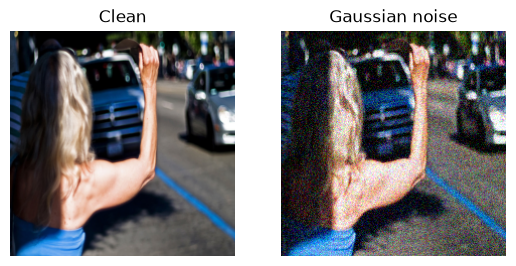

In [76]:
import matplotlib.pyplot as plt

plt.figure()

plt.subplot(1, 2, 1)
plt.imshow(images[0].permute(1, 2, 0))
plt.title("Clean")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(noisy_images[0].permute(1, 2, 0))
plt.title("Gaussian noise")
plt.axis("off")

plt.show()

In [ ]:


model.eval()
images_list = []
texts_list = []
for images,captions,masks in test_loader:
    with torch.no_grad() :
        images = images.to(device)
        images = add_gaussian_noise(images, sigma=0.1)
        captions = captions.to(device)
        masks = masks.to(device)
        image_features = model.image_encoder(images)
        image_embedding = model.projection_image(image_features)
        images_list.append(image_embedding)

        text_features = model.text_encoder(captions,masks)
        text_emdedding = model.projection_text(text_features)
        texts_list.append(text_emdedding)

images_list_cat = torch.cat(images_list,dim=0)
texts_list_cat = torch.cat(texts_list,dim=0)    
similarities_gaussian = images_list_cat @ texts_list_cat.T

In [ ]:
print("Gaussian noise sigma=0.1")

print("Image → Text")
print("R@1 :", recall_at_k(similarities_gaussian, 1))
print("R@5 :", recall_at_k(similarities_gaussian, 5))
print("R@10:", recall_at_k(similarities_gaussian, 10))

print("\nText → Image")
print("R@1 :", recall_at_k(similarities_gaussian.T, 1))
print("R@5 :", recall_at_k(similarities_gaussian.T, 5))
print("R@10:", recall_at_k(similarities_gaussian.T, 10))

Gaussian noise sigma=0.1
Image → Text
R@1 : 0.006000000052154064
R@5 : 0.03200000151991844
R@10: 0.06700000166893005

Text → Image
R@1 : 0.009000000543892384
R@5 : 0.04100000113248825
R@10: 0.08000000566244125


Text→Image semble légèrement plus robuste qu’Image→Text ici. Par exemple, R@10 conserve 8.0 % contre 6.7 %. On ne conclut rien de définitif avec une seule corruption, mais c’est quelque chose à surveiller.

In [77]:
SEED = 42
torch.manual_seed(SEED)

In [ ]:
sigmas = [0.0, 0.05, 0.1, 0.2]

def evaluate_gaussian_noise(sigma):
    torch.manual_seed(SEED)
    model.eval()
    images_list = []
    texts_list = []
    for images,captions,masks in test_loader:
        with torch.no_grad() :
            images = images.to(device)
            images = add_gaussian_noise(images, sigma=sigma)
            captions = captions.to(device)
            masks = masks.to(device)
            image_features = model.image_encoder(images)
            image_embedding = model.projection_image(image_features)
            images_list.append(image_embedding)

            text_features = model.text_encoder(captions,masks)
            text_emdedding = model.projection_text(text_features)
            texts_list.append(text_emdedding)

    images_list_cat = torch.cat(images_list,dim=0)
    texts_list_cat = torch.cat(texts_list,dim=0)    
    similarities_gaussian = images_list_cat @ texts_list_cat.T
    i2t_r1 = recall_at_k(similarities_gaussian, 1)
    i2t_r5 = recall_at_k(similarities_gaussian, 5)
    i2t_r10 = recall_at_k(similarities_gaussian, 10)

    t2i_r1 = recall_at_k(similarities_gaussian.T, 1)
    t2i_r5 = recall_at_k(similarities_gaussian.T, 5)
    t2i_r10 = recall_at_k(similarities_gaussian.T, 10)

    return {
        "image_to_text": {
            "R@1": i2t_r1,
            "R@5": i2t_r5,
            "R@10": i2t_r10
        },
        "text_to_image":{
            "R@1" : t2i_r1,
            "R@5" : t2i_r5,
            "R@10" : t2i_r10

        }
    }

In [80]:
checkpoint = torch.load(
    "../models/best_baseline.pt",
    map_location=device
)

model.load_state_dict(checkpoint["model_state"])
model.to(device)
model.eval()

print(checkpoint["epoch"])
print(checkpoint["val_loss"])

24
2.665776379406452


In [81]:
test_dataset = Flickr8kDataset(
    dataset["test"],
    training=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [82]:
print(checkpoint["epoch"])
print(checkpoint["val_loss"])
print(len(test_dataset))

24
2.665776379406452
1000


In [83]:
images, captions, masks = next(iter(test_loader))
images = images.to(device)

images_sigma0 = add_gaussian_noise(images, sigma=0.0)

print((images - images_sigma0).abs().max())

tensor(0., device='cuda:0')


In [84]:
clean_results = evaluate_gaussian_noise(0.0)
print(clean_results)

{'image_to_text': {'R@1': 0.021000001579523087, 'R@5': 0.09800000488758087, 'R@10': 0.16500000655651093}, 'text_to_image': {'R@1': 0.02500000037252903, 'R@5': 0.10200000554323196, 'R@10': 0.16500000655651093}}


In [85]:
sigmas = [0.05, 0.1, 0.2]

gaussian_results = {}

for sigma in sigmas:
    gaussian_results[sigma] = evaluate_gaussian_noise(sigma)
    print(f"sigma = {sigma}")
    print(gaussian_results[sigma])

sigma = 0.05
{'image_to_text': {'R@1': 0.018000001087784767, 'R@5': 0.07900000363588333, 'R@10': 0.12400000542402267}, 'text_to_image': {'R@1': 0.023000001907348633, 'R@5': 0.0860000029206276, 'R@10': 0.14400000870227814}}
sigma = 0.1
{'image_to_text': {'R@1': 0.01100000087171793, 'R@5': 0.03500000014901161, 'R@10': 0.06599999964237213}, 'text_to_image': {'R@1': 0.009000000543892384, 'R@5': 0.049000002443790436, 'R@10': 0.10100000351667404}}
sigma = 0.2
{'image_to_text': {'R@1': 0.003000000026077032, 'R@5': 0.015000000596046448, 'R@10': 0.026000000536441803}, 'text_to_image': {'R@1': 0.007000000216066837, 'R@5': 0.02800000086426735, 'R@10': 0.04700000211596489}}


In [86]:
gaussian_results[0.0] = clean_results

Le baseline apprend des représentations multimodales utiles sur des images propres, mais elles sont fortement sensibles au bruit gaussien, en particulier lorsque l’intensité de corruption augmente

In [87]:
import torchvision.transforms.functional as TF

In [ ]:
def add_gaussian_blur(images, kernel_size, sigma):
    blurred_images = TF.gaussian_blur(
        images,
        kernel_size=[kernel_size,kernel_size],
        sigma=[sigma,sigma]
    )

    return blurred_images

kernel_size=[7, 7]
sigma=[1.0, 1.0]

In [89]:
images, captions, masks = next(iter(test_loader))

blurred_images = add_gaussian_blur(
    images,
    kernel_size=7,
    sigma=1.0
)

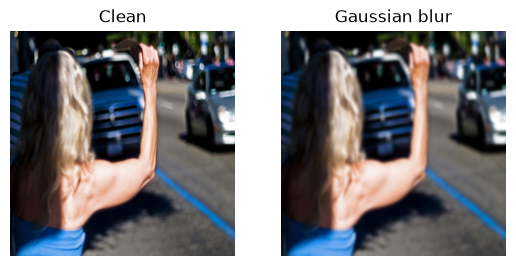

In [90]:
plt.figure()

plt.subplot(1, 2, 1)
plt.imshow(images[0].permute(1, 2, 0))
plt.title("Clean")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred_images[0].permute(1, 2, 0))
plt.title("Gaussian blur")
plt.axis("off")

plt.show()

In [93]:
def evaluate_gaussian_blur(kernel_size, sigma):
    model.eval()
    images_list = []
    texts_list = []

    for images, captions, masks in test_loader:
        with torch.no_grad():

            images = images.to(device)

          
            images = add_gaussian_blur(images,kernel_size,sigma)
            captions = captions.to(device)
            masks = masks.to(device)

            image_features = model.image_encoder(images)
            image_embedding = model.projection_image(image_features)
            images_list.append(image_embedding)

            text_features = model.text_encoder(captions, masks)
            text_embedding = model.projection_text(text_features)
            texts_list.append(text_embedding)

    images_list_cat = torch.cat(images_list, dim=0)
    texts_list_cat = torch.cat(texts_list, dim=0)

    similarities_blur = images_list_cat @ texts_list_cat.T
    i2t_r1 = recall_at_k(similarities_blur, 1)
    i2t_r5 = recall_at_k(similarities_blur, 5)
    i2t_r10 = recall_at_k(similarities_blur, 10)

    t2i_r1 = recall_at_k(similarities_blur.T, 1)
    t2i_r5 = recall_at_k(similarities_blur.T, 5)
    t2i_r10 = recall_at_k(similarities_blur.T, 10)

    return {
        "image_to_text": {
            "R@1": i2t_r1,
            "R@5": i2t_r5,
            "R@10": i2t_r10
        },
        "text_to_image":{
            "R@1" : t2i_r1,
            "R@5" : t2i_r5,
            "R@10" : t2i_r10

        }
    }

In [94]:
blur_results = evaluate_gaussian_blur(
    kernel_size=7,
    sigma=1.0
)

print(blur_results)

{'image_to_text': {'R@1': 0.012000000104308128, 'R@5': 0.06599999964237213, 'R@10': 0.11400000751018524}, 'text_to_image': {'R@1': 0.01600000075995922, 'R@5': 0.07700000703334808, 'R@10': 0.12400000542402267}}


In [95]:
blur_settings = [
    (3, 0.5),
    (7, 1.0),
    (11, 2.0)
]

all_blur_results = {}

for kernel_size, sigma in blur_settings:
    result = evaluate_gaussian_blur(kernel_size, sigma)
    all_blur_results[(kernel_size, sigma)] = result

    print(f"kernel_size={kernel_size}, sigma={sigma}")
    print(result)

kernel_size=3, sigma=0.5
{'image_to_text': {'R@1': 0.024000000208616257, 'R@5': 0.0860000029206276, 'R@10': 0.15700000524520874}, 'text_to_image': {'R@1': 0.026000000536441803, 'R@5': 0.09300000220537186, 'R@10': 0.14900000393390656}}
kernel_size=7, sigma=1.0
{'image_to_text': {'R@1': 0.012000000104308128, 'R@5': 0.06599999964237213, 'R@10': 0.11400000751018524}, 'text_to_image': {'R@1': 0.01600000075995922, 'R@5': 0.07700000703334808, 'R@10': 0.12400000542402267}}
kernel_size=11, sigma=2.0
{'image_to_text': {'R@1': 0.01100000087171793, 'R@5': 0.04800000041723251, 'R@10': 0.09000000357627869}, 'text_to_image': {'R@1': 0.014000000432133675, 'R@5': 0.05400000140070915, 'R@10': 0.09400000423192978}}


plus le blur est fort
        ↓
plus les détails et contours disparaissent
        ↓
l'image encoder produit une représentation moins précise
        ↓
le retrieval se dégrade

Comparé au Gaussian noise, on observe aussi quelque chose d'intéressant : le modèle semble nettement plus sensible au bruit aléatoire qu'au blur.

In [96]:
def adjust_brightness(images, factor):
    bright_images = TF.adjust_brightness(images,factor)
    return bright_images

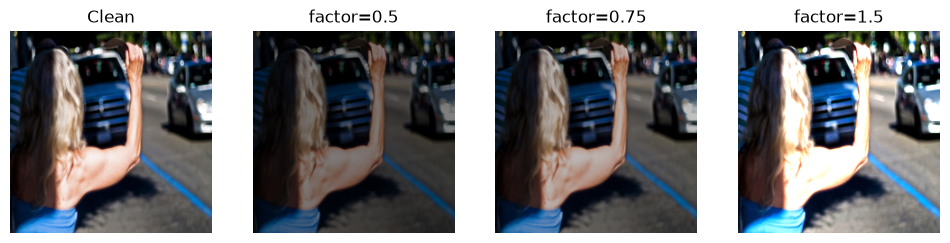

In [98]:
images, captions, masks = next(iter(test_loader))

dark_images = adjust_brightness(images, 0.5)
slightly_dark_images = adjust_brightness(images, 0.75)
bright_images = adjust_brightness(images, 1.5)

plt.figure(figsize=(12, 4))

plt.subplot(1, 4, 1)
plt.imshow(images[0].permute(1, 2, 0))
plt.title("Clean")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(dark_images[0].permute(1, 2, 0))
plt.title("factor=0.5")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(slightly_dark_images[0].permute(1, 2, 0))
plt.title("factor=0.75")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(bright_images[0].permute(1, 2, 0))
plt.title("factor=1.5")
plt.axis("off")

plt.show()

In [99]:
def evaluate_brightness(factor):
    model.eval()
    images_list = []
    texts_list = []

    for images, captions, masks in test_loader:
        with torch.no_grad():

            images = images.to(device)

            
            images = adjust_brightness(images,factor)

            captions = captions.to(device)
            masks = masks.to(device)

            image_features = model.image_encoder(images)
            image_embedding = model.projection_image(image_features)
            images_list.append(image_embedding)

            text_features = model.text_encoder(captions, masks)
            text_embedding = model.projection_text(text_features)
            texts_list.append(text_embedding)

    images_list_cat = torch.cat(images_list, dim=0)
    texts_list_cat = torch.cat(texts_list, dim=0)

    similarities_brightness = images_list_cat @ texts_list_cat.T
    i2t_r1 = recall_at_k(similarities_brightness, 1)
    i2t_r5 = recall_at_k(similarities_brightness, 5)
    i2t_r10 = recall_at_k(similarities_brightness, 10)

    t2i_r1 = recall_at_k(similarities_brightness.T, 1)
    t2i_r5 = recall_at_k(similarities_brightness.T, 5)
    t2i_r10 = recall_at_k(similarities_brightness.T, 10)

    return {
        "image_to_text": {
            "R@1": i2t_r1,
            "R@5": i2t_r5,
            "R@10": i2t_r10
        },
        "text_to_image":{
            "R@1" : t2i_r1,
            "R@5" : t2i_r5,
            "R@10" : t2i_r10

        }
    }

In [100]:
brightness_factors = [0.5, 0.75, 1.0, 1.25, 1.5]

brightness_results = {}

for factor in brightness_factors:
    brightness_results[factor] = evaluate_brightness(factor)

    print(f"factor = {factor}")
    print(brightness_results[factor])

factor = 0.5
{'image_to_text': {'R@1': 0.012000000104308128, 'R@5': 0.04700000211596489, 'R@10': 0.08000000566244125}, 'text_to_image': {'R@1': 0.020000001415610313, 'R@5': 0.0560000017285347, 'R@10': 0.10700000822544098}}
factor = 0.75
{'image_to_text': {'R@1': 0.01900000125169754, 'R@5': 0.07500000298023224, 'R@10': 0.14000000059604645}, 'text_to_image': {'R@1': 0.02200000174343586, 'R@5': 0.08800000697374344, 'R@10': 0.14100000262260437}}
factor = 1.0
{'image_to_text': {'R@1': 0.021000001579523087, 'R@5': 0.09800000488758087, 'R@10': 0.16500000655651093}, 'text_to_image': {'R@1': 0.02500000037252903, 'R@5': 0.10200000554323196, 'R@10': 0.16500000655651093}}
factor = 1.25
{'image_to_text': {'R@1': 0.020000001415610313, 'R@5': 0.0950000062584877, 'R@10': 0.164000004529953}, 'text_to_image': {'R@1': 0.027000000700354576, 'R@5': 0.09700000286102295, 'R@10': 0.17100000381469727}}
factor = 1.5
{'image_to_text': {'R@1': 0.017000000923871994, 'R@5': 0.07500000298023224, 'R@10': 0.1319999992

La première conclusion est que ton modèle est beaucoup plus sensible à l’assombrissement fort qu’à une légère augmentation de luminosité.

Gaussian noise → très destructeur
Gaussian blur  → dégradation progressive
Brightness     → surtout sensible aux images sombres

In [101]:
224*0.25


56.0

In [105]:
import math



def add_occlusion(images, fraction):
    B, C, H, W = images.shape

    occlusion_size = int(H * math.sqrt(fraction))

    center_h = H // 2
    center_w = W // 2

    half = occlusion_size // 2

    h_start = center_h - half
    h_end = center_h + half

    w_start = center_w - half
    w_end = center_w + half

    occluded_images = images.clone()

    occluded_images[:, :, h_start:h_end, w_start:w_end] = 0

    return occluded_images

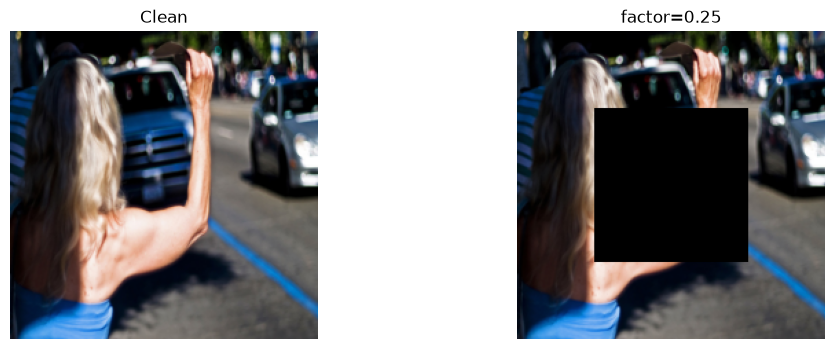

In [106]:
occluded = add_occlusion(images, 0.25)
images, captions, masks = next(iter(test_loader))


plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(images[0].permute(1, 2, 0))
plt.title("Clean")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(occluded[0].permute(1, 2, 0))
plt.title("factor=0.25")
plt.axis("off")



plt.show()

In [107]:
def evaluate_occlusion(fraction):
    model.eval()
    images_list = []
    texts_list = []

    for images, captions, masks in test_loader:
        with torch.no_grad():

            images = images.to(device)

            # appliquer l'occlusion ici
            images = add_occlusion(images,fraction)

            captions = captions.to(device)
            masks = masks.to(device)

            image_features = model.image_encoder(images)
            image_embedding = model.projection_image(image_features)
            images_list.append(image_embedding)

            text_features = model.text_encoder(captions, masks)
            text_embedding = model.projection_text(text_features)
            texts_list.append(text_embedding)

    images_list_cat = torch.cat(images_list, dim=0)
    texts_list_cat = torch.cat(texts_list, dim=0)

    similarities_occlusion = images_list_cat @ texts_list_cat.T
    i2t_r1 = recall_at_k(similarities_occlusion, 1)
    i2t_r5 = recall_at_k(similarities_occlusion, 5)
    i2t_r10 = recall_at_k(similarities_occlusion, 10)

    t2i_r1 = recall_at_k(similarities_occlusion.T, 1)
    t2i_r5 = recall_at_k(similarities_occlusion.T, 5)
    t2i_r10 = recall_at_k(similarities_occlusion.T, 10)

    return {
        "image_to_text": {
            "R@1": i2t_r1,
            "R@5": i2t_r5,
            "R@10": i2t_r10
        },
        "text_to_image": {
            "R@1": t2i_r1,
            "R@5": t2i_r5,
            "R@10": t2i_r10
        }
    }

In [108]:
fractions = [0.0, 0.10, 0.25, 0.40]

occlusion_results = {}

for fraction in fractions:
    occlusion_results[fraction] = evaluate_occlusion(fraction)

    print(f"fraction = {fraction}")
    print(occlusion_results[fraction])

fraction = 0.0
{'image_to_text': {'R@1': 0.021000001579523087, 'R@5': 0.09800000488758087, 'R@10': 0.16500000655651093}, 'text_to_image': {'R@1': 0.02500000037252903, 'R@5': 0.10200000554323196, 'R@10': 0.16500000655651093}}
fraction = 0.1
{'image_to_text': {'R@1': 0.018000001087784767, 'R@5': 0.05000000074505806, 'R@10': 0.09200000762939453}, 'text_to_image': {'R@1': 0.01600000075995922, 'R@5': 0.07100000232458115, 'R@10': 0.125}}
fraction = 0.25
{'image_to_text': {'R@1': 0.013000000268220901, 'R@5': 0.036000002175569534, 'R@10': 0.06200000271201134}, 'text_to_image': {'R@1': 0.013000000268220901, 'R@5': 0.0650000050663948, 'R@10': 0.09700000286102295}}
fraction = 0.4
{'image_to_text': {'R@1': 0.009000000543892384, 'R@5': 0.023000001907348633, 'R@10': 0.046000003814697266}, 'text_to_image': {'R@1': 0.010000000707805157, 'R@5': 0.052000001072883606, 'R@10': 0.0950000062584877}}


Le comportement est très clair : plus on cache de surface de l’image, plus le retrieval se dégrade.

Gaussian noise
→ très destructeur

Blur
→ dégradation progressive mais plus douce

Brightness
→ assez robuste aux variations modérées
→ beaucoup plus sensible aux images fortement sombres

Occlusion
→ forte dégradation quand de l'information visuelle disparaît


In [ ]:
def delete_words(captions, masks, deletion_rate):

    corrupted_captions = torch.zeros_like(captions)
    corrupted_masks = torch.zeros_like(masks)
    for i in range(captions.shape[0]):
        
        true_tokens = captions[i][masks[i] == 1]
       
        num_tokens = len(true_tokens)
        num_to_delete = min(
                            int(num_tokens * deletion_rate),
                            num_tokens - 1
                        )
        rand_numbs = torch.randperm(num_tokens,device=captions.device)
        delete_indices = rand_numbs[:num_to_delete]
        keep_mask = torch.ones(num_tokens, dtype=torch.bool,device=captions.device)
        keep_mask[delete_indices] = False
        kept_tokens = true_tokens[keep_mask]

        new_caption = torch.zeros_like(captions[i])
        new_mask = torch.zeros_like(masks[i])

        num_kept = len(kept_tokens)

        new_caption[:num_kept] = kept_tokens
        new_mask[:num_kept] = 1

        corrupted_captions[i] = new_caption
        corrupted_masks[i] = new_mask

       

    return corrupted_captions, corrupted_masks

In [110]:
captions, masks = next(iter(test_loader))[1:]

captions = captions.to(device)
masks = masks.to(device)

torch.manual_seed(42)

corrupted_captions, corrupted_masks = delete_words(
    captions,
    masks,
    deletion_rate=0.3
)

print("Original caption:")
print(captions[0])

print("\nOriginal mask:")
print(masks[0])

print("\nCorrupted caption:")
print(corrupted_captions[0])

print("\nCorrupted mask:")
print(corrupted_masks[0])

Original caption:
tensor([   2,  353,  243,    4,    2,  158,  157, 2177,   24,  789,  188,    2,
         289,   15,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0], device='cuda:0')

Original mask:
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0], device='cuda:0')

Corrupted caption:
tensor([   2,    4,    2,  158, 2177,   24,  789,  188,  289,   15,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0], device='cuda:0')

Corrupted mask:
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0], device='cuda:0')


In [111]:
print("Original tokens :", masks[0].sum().item())
print("Remaining tokens:", corrupted_masks[0].sum().item())

Original tokens : 14
Remaining tokens: 10


In [112]:
def evaluate_word_deletion(deletion_rate):
    torch.manual_seed(42)

    model.eval()
    images_list = []
    texts_list = []

    for images, captions, masks in test_loader:
        with torch.no_grad():

            images = images.to(device)
            captions = captions.to(device)
            masks = masks.to(device)

            corrupted_captions, corrupted_masks = delete_words(
                captions,
                masks,
                deletion_rate
            )

            image_features = model.image_encoder(images)
            image_embedding = model.projection_image(image_features)
            images_list.append(image_embedding)

            text_features = model.text_encoder(
                corrupted_captions,
                corrupted_masks
            )
            text_embedding = model.projection_text(text_features)
            texts_list.append(text_embedding)

    images_list_cat = torch.cat(images_list, dim=0)
    texts_list_cat = torch.cat(texts_list, dim=0)

    similarities_deletion = images_list_cat @ texts_list_cat.T

    i2t_r1 = recall_at_k(similarities_deletion, 1)
    i2t_r5 = recall_at_k(similarities_deletion, 5)
    i2t_r10 = recall_at_k(similarities_deletion, 10)

    t2i_r1 = recall_at_k(similarities_deletion.T, 1)
    t2i_r5 = recall_at_k(similarities_deletion.T, 5)
    t2i_r10 = recall_at_k(similarities_deletion.T, 10)

    return {
        "image_to_text": {
            "R@1": i2t_r1,
            "R@5": i2t_r5,
            "R@10": i2t_r10
        },
        "text_to_image": {
            "R@1": t2i_r1,
            "R@5": t2i_r5,
            "R@10": t2i_r10
        }
    }

In [113]:
deletion_rates = [0.0, 0.1, 0.2, 0.3]

word_deletion_results = {}

for rate in deletion_rates:
    word_deletion_results[rate] = evaluate_word_deletion(rate)

    print(f"deletion_rate = {rate}")
    print(word_deletion_results[rate])

deletion_rate = 0.0
{'image_to_text': {'R@1': 0.021000001579523087, 'R@5': 0.09800000488758087, 'R@10': 0.16500000655651093}, 'text_to_image': {'R@1': 0.02500000037252903, 'R@5': 0.10200000554323196, 'R@10': 0.16500000655651093}}
deletion_rate = 0.1
{'image_to_text': {'R@1': 0.018000001087784767, 'R@5': 0.08700000494718552, 'R@10': 0.15600000321865082}, 'text_to_image': {'R@1': 0.023000001907348633, 'R@5': 0.10400000214576721, 'R@10': 0.16200000047683716}}
deletion_rate = 0.2
{'image_to_text': {'R@1': 0.010000000707805157, 'R@5': 0.0820000022649765, 'R@10': 0.14000000059604645}, 'text_to_image': {'R@1': 0.027000000700354576, 'R@5': 0.09000000357627869, 'R@10': 0.14900000393390656}}
deletion_rate = 0.3
{'image_to_text': {'R@1': 0.012000000104308128, 'R@5': 0.07700000703334808, 'R@10': 0.12800000607967377}, 'text_to_image': {'R@1': 0.021000001579523087, 'R@5': 0.08500000089406967, 'R@10': 0.12400000542402267}}


word deletion est beaucoup moins destructeur que les corruptions image fortes.

Image → Text R@10
16.5 % → 12.8 %

Text → Image R@10
16.5 % → 12.4 %


In [115]:
def mask_words(captions, masks, masking_rate):

    corrupted_captions = captions.clone()
    corrupted_masks = masks.clone()

    for i in range(captions.shape[0]):

        valid_positions = torch.where(masks[i] == 1)[0]

        num_tokens = len(valid_positions)

        num_to_mask = min(
            int(num_tokens * masking_rate),
            num_tokens - 1
        )

        random_order = torch.randperm(
            num_tokens,
            device=captions.device
        )

        selected = random_order[:num_to_mask]

        positions_to_mask = valid_positions[selected]

        corrupted_captions[i, positions_to_mask] = 1

    return corrupted_captions, corrupted_masks

In [116]:
captions, masks = next(iter(test_loader))[1:]

captions = captions.to(device)
masks = masks.to(device)

torch.manual_seed(42)

corrupted_captions, corrupted_masks = mask_words(
    captions,
    masks,
    masking_rate=0.3
)

print("Original caption:")
print(captions[0])

print("\nOriginal mask:")
print(masks[0])

print("\nMasked caption:")
print(corrupted_captions[0])

print("\nMasked mask:")
print(corrupted_masks[0])

print("\nOriginal tokens :", masks[0].sum().item())
print("Valid tokens after masking:", corrupted_masks[0].sum().item())

Original caption:
tensor([   2,  353,  243,    4,    2,  158,  157, 2177,   24,  789,  188,    2,
         289,   15,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0], device='cuda:0')

Original mask:
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0], device='cuda:0')

Masked caption:
tensor([   2,    1,    1,    4,    2,  158,    1, 2177,   24,  789,  188,    1,
         289,   15,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0], device='cuda:0')

Masked mask:
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0], device='cuda:0')

Original tokens : 14
Valid tokens after masking: 14


In [117]:
def evaluate_word_masking(masking_rate):
    torch.manual_seed(42)

    model.eval()
    images_list = []
    texts_list = []

    for images, captions, masks in test_loader:
        with torch.no_grad():
            images = images.to(device)
            captions = captions.to(device)
            masks = masks.to(device)

            corrupted_captions, corrupted_masks = mask_words(
                captions,
                masks,
                masking_rate
            )

            image_features = model.image_encoder(images)
            image_embedding = model.projection_image(image_features)
            images_list.append(image_embedding)

            text_features = model.text_encoder(
                corrupted_captions,
                corrupted_masks
            )
            text_embedding = model.projection_text(text_features)
            texts_list.append(text_embedding)

    images_list_cat = torch.cat(images_list, dim=0)
    texts_list_cat = torch.cat(texts_list, dim=0)

    similarities_masking = images_list_cat @ texts_list_cat.T

    i2t_r1 = recall_at_k(similarities_masking, 1)
    i2t_r5 = recall_at_k(similarities_masking, 5)
    i2t_r10 = recall_at_k(similarities_masking, 10)

    t2i_r1 = recall_at_k(similarities_masking.T, 1)
    t2i_r5 = recall_at_k(similarities_masking.T, 5)
    t2i_r10 = recall_at_k(similarities_masking.T, 10)

    return {
        "image_to_text": {
            "R@1": i2t_r1,
            "R@5": i2t_r5,
            "R@10": i2t_r10
        },
        "text_to_image": {
            "R@1": t2i_r1,
            "R@5": t2i_r5,
            "R@10": t2i_r10
        }
    }

In [118]:
masking_rates = [0.0, 0.1, 0.2, 0.3]

word_masking_results = {}

for rate in masking_rates:
    word_masking_results[rate] = evaluate_word_masking(rate)

    print(f"masking_rate = {rate}")
    print(word_masking_results[rate])

masking_rate = 0.0
{'image_to_text': {'R@1': 0.021000001579523087, 'R@5': 0.09800000488758087, 'R@10': 0.16500000655651093}, 'text_to_image': {'R@1': 0.02500000037252903, 'R@5': 0.10200000554323196, 'R@10': 0.16500000655651093}}
masking_rate = 0.1
{'image_to_text': {'R@1': 0.017000000923871994, 'R@5': 0.08900000154972076, 'R@10': 0.15800000727176666}, 'text_to_image': {'R@1': 0.024000000208616257, 'R@5': 0.09600000083446503, 'R@10': 0.16700001060962677}}
masking_rate = 0.2
{'image_to_text': {'R@1': 0.015000000596046448, 'R@5': 0.08400000631809235, 'R@10': 0.15000000596046448}, 'text_to_image': {'R@1': 0.021000001579523087, 'R@5': 0.09200000762939453, 'R@10': 0.14400000870227814}}
masking_rate = 0.3
{'image_to_text': {'R@1': 0.015000000596046448, 'R@5': 0.08400000631809235, 'R@10': 0.12800000607967377}, 'text_to_image': {'R@1': 0.02200000174343586, 'R@5': 0.07700000703334808, 'R@10': 0.125}}


Le résultat ressemble beaucoup à word deletion : les performances baissent progressivement, mais restent relativement robustes jusqu’à 20–30 % de corruption.

30 % word deletion
I→T R@10 = 12.8 %
T→I R@10 = 12.4 %

30 % word masking
I→T R@10 = 12.8 %
T→I R@10 = 12.5 %

In [119]:
def swap_words(captions, masks, swap_rate):

    corrupted_captions = captions.clone()
    corrupted_masks = masks.clone()

    for i in range(captions.shape[0]):

        valid_positions = torch.where(masks[i] == 1)[0]

        num_tokens = len(valid_positions)

        num_to_swap = int(num_tokens * swap_rate)

        if num_to_swap % 2 != 0:
            num_to_swap -= 1

        random_order = torch.randperm(
            num_tokens,
            device=captions.device
        )

        selected = random_order[:num_to_swap]

        for j in range(0, num_to_swap, 2):
            pos1 = valid_positions[selected[j]]
            pos2 = valid_positions[selected[j + 1]]

            temp = corrupted_captions[i, pos1].clone()
            corrupted_captions[i, pos1] = corrupted_captions[i, pos2]
            corrupted_captions[i, pos2] = temp

    return corrupted_captions, corrupted_masks

In [120]:
captions, masks = next(iter(test_loader))[1:]

captions = captions.to(device)
masks = masks.to(device)

torch.manual_seed(42)

corrupted_captions, corrupted_masks = swap_words(
    captions,
    masks,
    swap_rate=0.3
)

print("Original caption:")
print(captions[0])

print("\nOriginal mask:")
print(masks[0])

print("\nSwapped caption:")
print(corrupted_captions[0])

print("\nSwapped mask:")
print(corrupted_masks[0])

Original caption:
tensor([   2,  353,  243,    4,    2,  158,  157, 2177,   24,  789,  188,    2,
         289,   15,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0], device='cuda:0')

Original mask:
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0], device='cuda:0')

Swapped caption:
tensor([   2,    2,  157,    4,    2,  158,  243, 2177,   24,  789,  188,  353,
         289,   15,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0], device='cuda:0')

Swapped mask:
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0], device='cuda:0')


In [121]:
original_tokens = captions[0][masks[0] == 1]
swapped_tokens = corrupted_captions[0][corrupted_masks[0] == 1]

print(torch.equal(
    torch.sort(original_tokens).values,
    torch.sort(swapped_tokens).values
))

True


In [122]:
def evaluate_word_swapping(swap_rate):
    torch.manual_seed(42)

    model.eval()
    images_list = []
    texts_list = []

    for images, captions, masks in test_loader:
        with torch.no_grad():

            images = images.to(device)
            captions = captions.to(device)
            masks = masks.to(device)

            corrupted_captions, corrupted_masks = swap_words(
                captions,
                masks,
                swap_rate
            )

            image_features = model.image_encoder(images)
            image_embedding = model.projection_image(image_features)
            images_list.append(image_embedding)

            text_features = model.text_encoder(
                corrupted_captions,
                corrupted_masks
            )
            text_embedding = model.projection_text(text_features)
            texts_list.append(text_embedding)

    images_list_cat = torch.cat(images_list, dim=0)
    texts_list_cat = torch.cat(texts_list, dim=0)

    similarities_swapping = images_list_cat @ texts_list_cat.T

    i2t_r1 = recall_at_k(similarities_swapping, 1)
    i2t_r5 = recall_at_k(similarities_swapping, 5)
    i2t_r10 = recall_at_k(similarities_swapping, 10)

    t2i_r1 = recall_at_k(similarities_swapping.T, 1)
    t2i_r5 = recall_at_k(similarities_swapping.T, 5)
    t2i_r10 = recall_at_k(similarities_swapping.T, 10)

    return {
        "image_to_text": {
            "R@1": i2t_r1,
            "R@5": i2t_r5,
            "R@10": i2t_r10
        },
        "text_to_image": {
            "R@1": t2i_r1,
            "R@5": t2i_r5,
            "R@10": t2i_r10
        }
    }

In [123]:
swap_rates = [0.0, 0.1, 0.2, 0.3]

word_swapping_results = {}

for rate in swap_rates:
    word_swapping_results[rate] = evaluate_word_swapping(rate)

    print(f"swap_rate = {rate}")
    print(word_swapping_results[rate])

swap_rate = 0.0
{'image_to_text': {'R@1': 0.021000001579523087, 'R@5': 0.09800000488758087, 'R@10': 0.16500000655651093}, 'text_to_image': {'R@1': 0.02500000037252903, 'R@5': 0.10200000554323196, 'R@10': 0.16500000655651093}}
swap_rate = 0.1
{'image_to_text': {'R@1': 0.021000001579523087, 'R@5': 0.09800000488758087, 'R@10': 0.16700001060962677}, 'text_to_image': {'R@1': 0.027000000700354576, 'R@5': 0.10300000756978989, 'R@10': 0.16500000655651093}}
swap_rate = 0.2
{'image_to_text': {'R@1': 0.021000001579523087, 'R@5': 0.10600000619888306, 'R@10': 0.1730000078678131}, 'text_to_image': {'R@1': 0.032999999821186066, 'R@5': 0.10100000351667404, 'R@10': 0.1720000058412552}}
swap_rate = 0.3
{'image_to_text': {'R@1': 0.02200000174343586, 'R@5': 0.10100000351667404, 'R@10': 0.16600000858306885}, 'text_to_image': {'R@1': 0.03200000151991844, 'R@5': 0.09600000083446503, 'R@10': 0.16700001060962677}}


In [124]:
swap_rates = [0.0, 0.2, 0.4, 0.6, 0.8]

word_swapping_results = {}

for rate in swap_rates:
    word_swapping_results[rate] = evaluate_word_swapping(rate)

    print(f"swap_rate = {rate}")
    print(word_swapping_results[rate])

swap_rate = 0.0
{'image_to_text': {'R@1': 0.021000001579523087, 'R@5': 0.09800000488758087, 'R@10': 0.16500000655651093}, 'text_to_image': {'R@1': 0.02500000037252903, 'R@5': 0.10200000554323196, 'R@10': 0.16500000655651093}}
swap_rate = 0.2
{'image_to_text': {'R@1': 0.021000001579523087, 'R@5': 0.10600000619888306, 'R@10': 0.1730000078678131}, 'text_to_image': {'R@1': 0.032999999821186066, 'R@5': 0.10100000351667404, 'R@10': 0.1720000058412552}}
swap_rate = 0.4
{'image_to_text': {'R@1': 0.02200000174343586, 'R@5': 0.10200000554323196, 'R@10': 0.164000004529953}, 'text_to_image': {'R@1': 0.02800000086426735, 'R@5': 0.09400000423192978, 'R@10': 0.15600000321865082}}
swap_rate = 0.6
{'image_to_text': {'R@1': 0.024000000208616257, 'R@5': 0.09600000083446503, 'R@10': 0.15800000727176666}, 'text_to_image': {'R@1': 0.029000001028180122, 'R@5': 0.09400000423192978, 'R@10': 0.1469999998807907}}
swap_rate = 0.8
{'image_to_text': {'R@1': 0.020000001415610313, 'R@5': 0.07900000363588333, 'R@10': 

Under the tested word-swapping corruption, retrieval performance remains relatively stable even at high swap rates, suggesting that the current text representation is more dependent on lexical/semantic content than on precise word ordering.

In [125]:
import random

def add_typo_to_word(word):

    if len(word) < 3:
        return word

    chars = list(word)

    position = random.randint(
        0,
        len(chars) - 2
    )
    temp = chars[position]
    # échanger chars[position]
    chars[position] = chars[position + 1]
    # et chars[position + 1]
    chars[position + 1] = temp

    return "".join(chars)

print(add_typo_to_word("running"))

runinng


In [140]:
def add_typos_to_caption(caption, typo_rate):

    words = caption.split()

    for i, word in enumerate(words):

        if len(word) >= 3 and random.random() < typo_rate:
            words[i] = add_typo_to_word(word)

    return " ".join(words)

In [130]:
random.seed(42)

caption = "a woman is walking near a blue car"

print(add_typos_to_caption(caption, 0.3))

a owman is walking near a blue car


In [134]:
random.seed(42)

caption = "a woman is walking near a blue car"
corrupted_caption = add_typos_to_caption(caption, 0.3)

original_encoded = encode_caption(caption, word_to_id)
corrupted_encoded = encode_caption(corrupted_caption, word_to_id)

print("Original :", caption)
print("Corrupted:", corrupted_caption)

print("\nOriginal IDs:")
print(original_encoded)

print("\nCorrupted IDs:")
print(corrupted_encoded)

Original : a woman is walking near a blue car
Corrupted: a owman is walking near a blue car

Original IDs:
[2, 243, 7, 151, 125, 2, 158, 788]

Corrupted IDs:
[2, 1, 7, 151, 125, 2, 158, 788]


In [ ]:
print("UNK original :", original_encoded.count(1))
print("UNK corrupted:", corrupted_encoded.count(1))


UNK original : 0
UNK corrupted: 1
UNK original : 0
UNK corrupted: 1


In [138]:
def evaluate_typos(typo_rate):

    random.seed(42)
    torch.manual_seed(42)

    typo_dataset = Flickr8kDataset(
        dataset["test"],
        training=False,
        typo_rate=typo_rate
    )

    typo_loader = DataLoader(
        typo_dataset,
        batch_size=32,
        shuffle=False
    )

    model.eval()

    all_image_embeddings = []
    all_text_embeddings = []

    with torch.no_grad():

        for images, captions, masks in typo_loader:

            images = images.to(device)
            captions = captions.to(device)
            masks = masks.to(device)

            # Image embeddings
            image_features = model.image_encoder(images)
            image_embeddings = model.projection_image(image_features)

            # Text embeddings
            text_features = model.text_encoder(
                captions,
                masks
            )
            text_embeddings = model.projection_text(text_features)

            all_image_embeddings.append(
                image_embeddings.cpu()
            )

            all_text_embeddings.append(
                text_embeddings.cpu()
            )

    all_image_embeddings = torch.cat(
        all_image_embeddings,
        dim=0
    )

    all_text_embeddings = torch.cat(
        all_text_embeddings,
        dim=0
    )

    similarities = (
        all_image_embeddings
        @ all_text_embeddings.T
    )

    results = {
        "typo_rate": typo_rate,

        "image_to_text": {
            "R@1": recall_at_k(similarities, 1),
            "R@5": recall_at_k(similarities, 5),
            "R@10": recall_at_k(similarities, 10)
        },

        "text_to_image": {
            "R@1": recall_at_k(similarities.T, 1),
            "R@5": recall_at_k(similarities.T, 5),
            "R@10": recall_at_k(similarities.T, 10)
        }
    }

    return results

In [139]:
typo_rates = [
    0.0,
    0.1,
    0.2,
    0.3
]

typo_results = []

for rate in typo_rates:

    results = evaluate_typos(rate)

    typo_results.append(results)

    print(f"\nTypo rate = {rate}")

    print(
        "Image -> Text:",
        results["image_to_text"]
    )

    print(
        "Text -> Image:",
        results["text_to_image"]
    )


Typo rate = 0.0
Image -> Text: {'R@1': 0.020999999716877937, 'R@5': 0.09799999743700027, 'R@10': 0.16500000655651093}
Text -> Image: {'R@1': 0.02500000037252903, 'R@5': 0.10199999809265137, 'R@10': 0.16500000655651093}

Typo rate = 0.1
Image -> Text: {'R@1': 0.019999999552965164, 'R@5': 0.09099999815225601, 'R@10': 0.16500000655651093}
Text -> Image: {'R@1': 0.026000000536441803, 'R@5': 0.10000000149011612, 'R@10': 0.16599999368190765}

Typo rate = 0.2
Image -> Text: {'R@1': 0.027000000700354576, 'R@5': 0.08100000023841858, 'R@10': 0.13899999856948853}
Text -> Image: {'R@1': 0.024000000208616257, 'R@5': 0.08399999886751175, 'R@10': 0.15199999511241913}

Typo rate = 0.3
Image -> Text: {'R@1': 0.01899999938905239, 'R@5': 0.07500000298023224, 'R@10': 0.13899999856948853}
Text -> Image: {'R@1': 0.02199999988079071, 'R@5': 0.07100000232458115, 'R@10': 0.12200000137090683}


In [141]:
random.seed(42)

caption = "a woman is walking near a blue car"

print(add_typos_to_caption(caption, 0.3))

a woman is wakling enar a blue car


In [142]:
typo_rates = [0.0, 0.1, 0.2, 0.3]

for rate in typo_rates:
    results = evaluate_typos(rate)

    print(f"\nTypo rate = {rate}")
    print("Image -> Text:", results["image_to_text"])
    print("Text -> Image:", results["text_to_image"])


Typo rate = 0.0
Image -> Text: {'R@1': 0.020999999716877937, 'R@5': 0.09799999743700027, 'R@10': 0.16500000655651093}
Text -> Image: {'R@1': 0.02500000037252903, 'R@5': 0.10199999809265137, 'R@10': 0.16500000655651093}

Typo rate = 0.1
Image -> Text: {'R@1': 0.017000000923871994, 'R@5': 0.08699999749660492, 'R@10': 0.16200000047683716}
Text -> Image: {'R@1': 0.020999999716877937, 'R@5': 0.09300000220537186, 'R@10': 0.15199999511241913}

Typo rate = 0.2
Image -> Text: {'R@1': 0.02199999988079071, 'R@5': 0.07900000363588333, 'R@10': 0.14800000190734863}
Text -> Image: {'R@1': 0.01899999938905239, 'R@5': 0.07800000160932541, 'R@10': 0.1379999965429306}

Typo rate = 0.3
Image -> Text: {'R@1': 0.014000000432133675, 'R@5': 0.08500000089406967, 'R@10': 0.15000000596046448}
Text -> Image: {'R@1': 0.023000000044703484, 'R@5': 0.07500000298023224, 'R@10': 0.13199999928474426}


In [143]:
import json

robustness_results = {

    "metadata": {
        "checkpoint_epoch": 24,
        "test_size": 1000,
        "caption_mode": "caption_0",
        "seed": 42
    },

    "clean": {
        "image_to_text": {
            "R@1": 0.021,
            "R@5": 0.098,
            "R@10": 0.165
        },
        "text_to_image": {
            "R@1": 0.025,
            "R@5": 0.102,
            "R@10": 0.165
        }
    },

    "image_corruptions": {

        "gaussian_noise": {
            "0.05": {
                "image_to_text": {"R@1": 0.018, "R@5": 0.079, "R@10": 0.124},
                "text_to_image": {"R@1": 0.023, "R@5": 0.086, "R@10": 0.144}
            },
            "0.10": {
                "image_to_text": {"R@1": 0.011, "R@5": 0.035, "R@10": 0.066},
                "text_to_image": {"R@1": 0.009, "R@5": 0.049, "R@10": 0.101}
            },
            "0.20": {
                "image_to_text": {"R@1": 0.003, "R@5": 0.015, "R@10": 0.026},
                "text_to_image": {"R@1": 0.007, "R@5": 0.028, "R@10": 0.047}
            }
        },

        "gaussian_blur": {
            "k3_sigma0.5": {
                "image_to_text": {"R@1": 0.024, "R@5": 0.086, "R@10": 0.157},
                "text_to_image": {"R@1": 0.026, "R@5": 0.093, "R@10": 0.149}
            },
            "k7_sigma1.0": {
                "image_to_text": {"R@1": 0.012, "R@5": 0.066, "R@10": 0.114},
                "text_to_image": {"R@1": 0.016, "R@5": 0.077, "R@10": 0.124}
            },
            "k11_sigma2.0": {
                "image_to_text": {"R@1": 0.011, "R@5": 0.048, "R@10": 0.090},
                "text_to_image": {"R@1": 0.014, "R@5": 0.054, "R@10": 0.094}
            }
        },

        "brightness": {
            "0.50": {
                "image_to_text": {"R@1": 0.012, "R@5": 0.047, "R@10": 0.080},
                "text_to_image": {"R@1": 0.020, "R@5": 0.056, "R@10": 0.107}
            },
            "0.75": {
                "image_to_text": {"R@1": 0.019, "R@5": 0.075, "R@10": 0.140},
                "text_to_image": {"R@1": 0.022, "R@5": 0.088, "R@10": 0.141}
            },
            "1.25": {
                "image_to_text": {"R@1": 0.020, "R@5": 0.095, "R@10": 0.164},
                "text_to_image": {"R@1": 0.027, "R@5": 0.097, "R@10": 0.171}
            },
            "1.50": {
                "image_to_text": {"R@1": 0.017, "R@5": 0.075, "R@10": 0.132},
                "text_to_image": {"R@1": 0.023, "R@5": 0.085, "R@10": 0.147}
            }
        },

        "occlusion": {
            "0.10": {
                "image_to_text": {"R@1": 0.018, "R@5": 0.050, "R@10": 0.092},
                "text_to_image": {"R@1": 0.016, "R@5": 0.071, "R@10": 0.125}
            },
            "0.25": {
                "image_to_text": {"R@1": 0.013, "R@5": 0.036, "R@10": 0.062},
                "text_to_image": {"R@1": 0.013, "R@5": 0.065, "R@10": 0.097}
            },
            "0.40": {
                "image_to_text": {"R@1": 0.009, "R@5": 0.023, "R@10": 0.046},
                "text_to_image": {"R@1": 0.010, "R@5": 0.052, "R@10": 0.095}
            }
        }
    },

    "text_corruptions": {

        "word_deletion": {
            "0.10": {
                "image_to_text": {"R@1": 0.018, "R@5": 0.087, "R@10": 0.156},
                "text_to_image": {"R@1": 0.023, "R@5": 0.104, "R@10": 0.162}
            },
            "0.20": {
                "image_to_text": {"R@1": 0.010, "R@5": 0.082, "R@10": 0.140},
                "text_to_image": {"R@1": 0.027, "R@5": 0.090, "R@10": 0.149}
            },
            "0.30": {
                "image_to_text": {"R@1": 0.012, "R@5": 0.077, "R@10": 0.128},
                "text_to_image": {"R@1": 0.021, "R@5": 0.085, "R@10": 0.124}
            }
        },

        "word_masking": {
            "0.10": {
                "image_to_text": {"R@1": 0.017, "R@5": 0.089, "R@10": 0.158},
                "text_to_image": {"R@1": 0.024, "R@5": 0.096, "R@10": 0.167}
            },
            "0.20": {
                "image_to_text": {"R@1": 0.015, "R@5": 0.084, "R@10": 0.150},
                "text_to_image": {"R@1": 0.021, "R@5": 0.092, "R@10": 0.144}
            },
            "0.30": {
                "image_to_text": {"R@1": 0.015, "R@5": 0.084, "R@10": 0.128},
                "text_to_image": {"R@1": 0.022, "R@5": 0.077, "R@10": 0.125}
            }
        },

        "word_swapping": {
            "0.20": {
                "image_to_text": {"R@1": 0.021, "R@5": 0.106, "R@10": 0.173},
                "text_to_image": {"R@1": 0.033, "R@5": 0.101, "R@10": 0.172}
            },
            "0.40": {
                "image_to_text": {"R@1": 0.022, "R@5": 0.102, "R@10": 0.164},
                "text_to_image": {"R@1": 0.028, "R@5": 0.094, "R@10": 0.156}
            },
            "0.60": {
                "image_to_text": {"R@1": 0.024, "R@5": 0.096, "R@10": 0.158},
                "text_to_image": {"R@1": 0.029, "R@5": 0.094, "R@10": 0.147}
            },
            "0.80": {
                "image_to_text": {"R@1": 0.020, "R@5": 0.079, "R@10": 0.142},
                "text_to_image": {"R@1": 0.026, "R@5": 0.083, "R@10": 0.142}
            }
        },

        "typos": {
            "0.10": {
                "image_to_text": {"R@1": 0.017, "R@5": 0.087, "R@10": 0.162},
                "text_to_image": {"R@1": 0.021, "R@5": 0.093, "R@10": 0.152}
            },
            "0.20": {
                "image_to_text": {"R@1": 0.022, "R@5": 0.079, "R@10": 0.148},
                "text_to_image": {"R@1": 0.019, "R@5": 0.078, "R@10": 0.138}
            },
            "0.30": {
                "image_to_text": {"R@1": 0.014, "R@5": 0.085, "R@10": 0.150},
                "text_to_image": {"R@1": 0.023, "R@5": 0.075, "R@10": 0.132}
            }
        }
    }
}

In [144]:
with open(
    "../results/robustness_results.json",
    "w"
) as f:

    json.dump(
        robustness_results,
        f,
        indent=4
    )

In [145]:
with open(
    "../results/robustness_results.json",
    "r"
) as f:

    loaded_results = json.load(f)

print(loaded_results["clean"])

{'image_to_text': {'R@1': 0.021, 'R@5': 0.098, 'R@10': 0.165}, 'text_to_image': {'R@1': 0.025, 'R@5': 0.102, 'R@10': 0.165}}


# graph

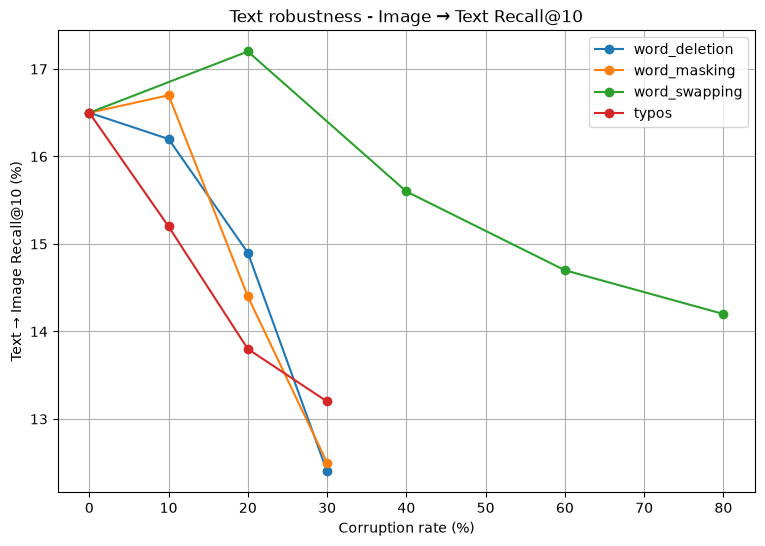

In [149]:
import matplotlib.pyplot as plt

clean_r10 = robustness_results["clean"]["text_to_image"]["R@10"]

text_results = robustness_results["text_corruptions"]

plt.figure(figsize=(9, 6))

for corruption_name, corruption_data in text_results.items():

    rates = [0.0]
    r10_scores = [clean_r10]

    for rate, metrics in corruption_data.items():
        rates.append(float(rate))
        r10_scores.append(
            metrics["text_to_image"]["R@10"]
        )

    
    pairs = sorted(zip(rates, r10_scores))

    rates = [x[0] * 100 for x in pairs]
    r10_scores = [x[1] * 100 for x in pairs]

    plt.plot(
        rates,
        r10_scores,
        marker="o",
        label=corruption_name
    )

plt.xlabel("Corruption rate (%)")
plt.ylabel("Text → Image Recall@10 (%)")
plt.title("Text robustness - Image → Text Recall@10")
plt.legend()
plt.grid(True)

plt.show()

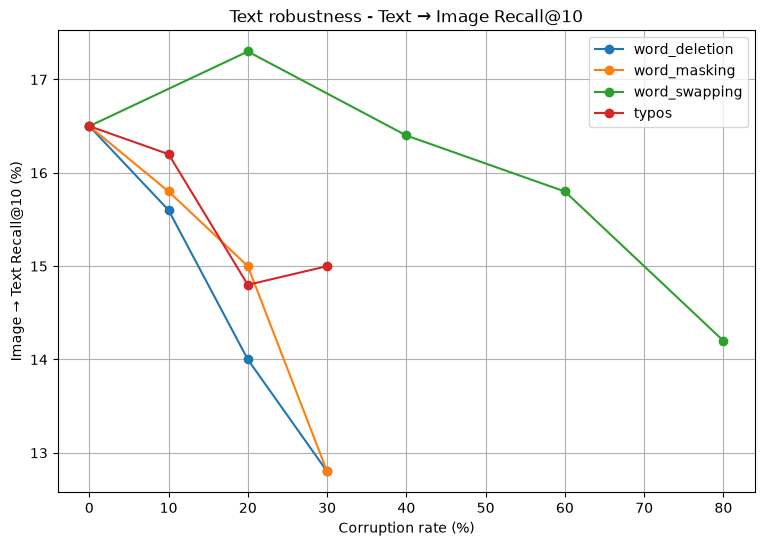

In [150]:
import matplotlib.pyplot as plt

clean_r10 = robustness_results["clean"]["image_to_text"]["R@10"]

text_results = robustness_results["text_corruptions"]

plt.figure(figsize=(9, 6))

for corruption_name, corruption_data in text_results.items():

    rates = [0.0]
    r10_scores = [clean_r10]

    for rate, metrics in corruption_data.items():
        rates.append(float(rate))
        r10_scores.append(
            metrics["image_to_text"]["R@10"]
        )

    
    pairs = sorted(zip(rates, r10_scores))

    rates = [x[0] * 100 for x in pairs]
    r10_scores = [x[1] * 100 for x in pairs]

    plt.plot(
        rates,
        r10_scores,
        marker="o",
        label=corruption_name
    )

plt.xlabel("Corruption rate (%)")
plt.ylabel("Image → Text Recall@10 (%)")
plt.title("Text robustness - Text → Image Recall@10")
plt.legend()
plt.grid(True)

plt.show()

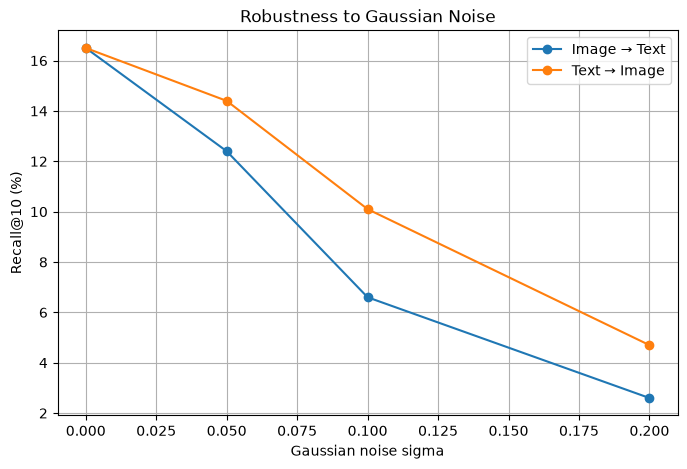

In [151]:
noise_levels = [0.0, 0.05, 0.10, 0.20]

noise_i2t = [
    0.165,
    0.124,
    0.066,
    0.026
]

noise_t2i = [
    0.165,
    0.144,
    0.101,
    0.047
]

plt.figure(figsize=(8, 5))

plt.plot(
    noise_levels,
    [x * 100 for x in noise_i2t],
    marker="o",
    label="Image → Text"
)

plt.plot(
    noise_levels,
    [x * 100 for x in noise_t2i],
    marker="o",
    label="Text → Image"
)

plt.xlabel("Gaussian noise sigma")
plt.ylabel("Recall@10 (%)")
plt.title("Robustness to Gaussian Noise")
plt.legend()
plt.grid(True)

plt.show()

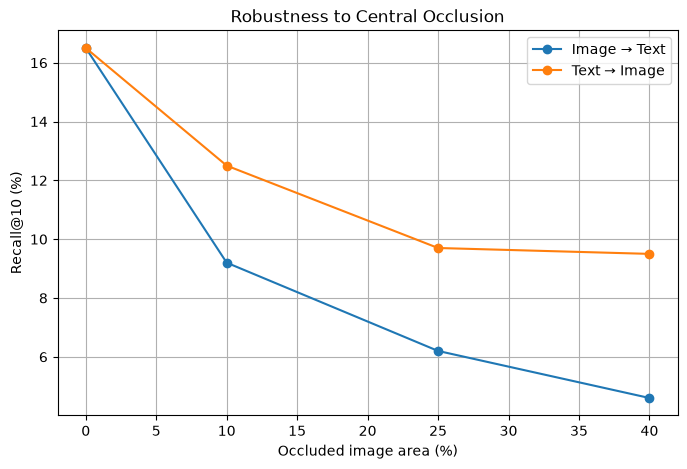

In [152]:
occlusion_levels = [0.0, 0.10, 0.25, 0.40]

occlusion_i2t = [
    0.165,
    0.092,
    0.062,
    0.046
]

occlusion_t2i = [
    0.165,
    0.125,
    0.097,
    0.095
]

plt.figure(figsize=(8, 5))

plt.plot(
    [x * 100 for x in occlusion_levels],
    [x * 100 for x in occlusion_i2t],
    marker="o",
    label="Image → Text"
)

plt.plot(
    [x * 100 for x in occlusion_levels],
    [x * 100 for x in occlusion_t2i],
    marker="o",
    label="Text → Image"
)

plt.xlabel("Occluded image area (%)")
plt.ylabel("Recall@10 (%)")
plt.title("Robustness to Central Occlusion")
plt.legend()
plt.grid(True)

plt.show()

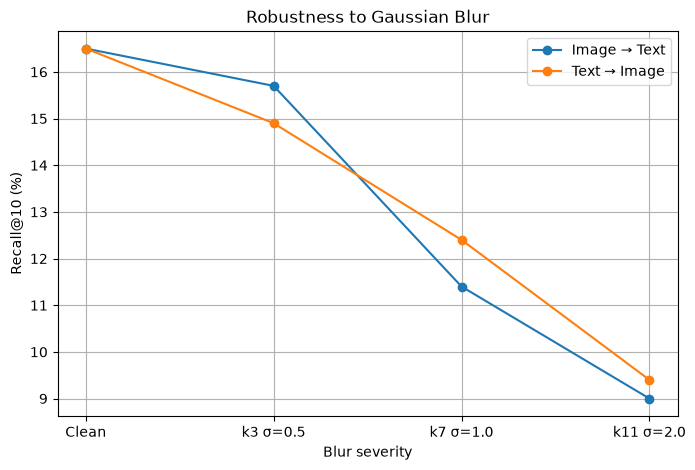

In [153]:
blur_labels = [
    "Clean",
    "k3 σ=0.5",
    "k7 σ=1.0",
    "k11 σ=2.0"
]

blur_i2t = [
    0.165,
    0.157,
    0.114,
    0.090
]

blur_t2i = [
    0.165,
    0.149,
    0.124,
    0.094
]

x = range(len(blur_labels))

plt.figure(figsize=(8, 5))

plt.plot(
    x,
    [v * 100 for v in blur_i2t],
    marker="o",
    label="Image → Text"
)

plt.plot(
    x,
    [v * 100 for v in blur_t2i],
    marker="o",
    label="Text → Image"
)

plt.xticks(x, blur_labels)

plt.xlabel("Blur severity")
plt.ylabel("Recall@10 (%)")
plt.title("Robustness to Gaussian Blur")

plt.legend()
plt.grid(True)

plt.show()

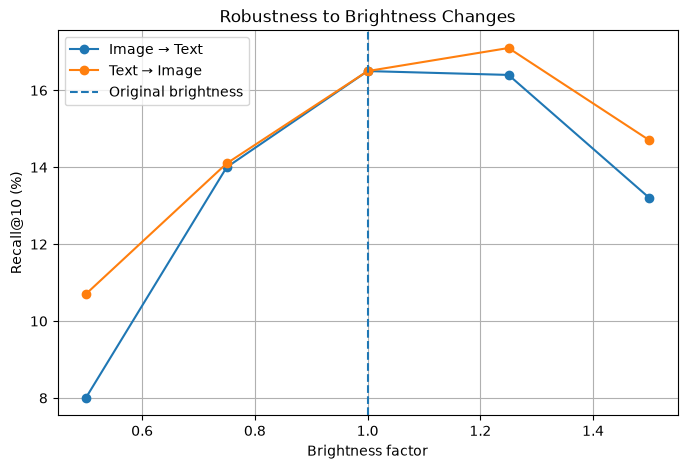

In [154]:
brightness_levels = [
    0.5,
    0.75,
    1.0,
    1.25,
    1.5
]

brightness_i2t = [
    0.080,
    0.140,
    0.165,
    0.164,
    0.132
]

brightness_t2i = [
    0.107,
    0.141,
    0.165,
    0.171,
    0.147
]

plt.figure(figsize=(8, 5))

plt.plot(
    brightness_levels,
    [v * 100 for v in brightness_i2t],
    marker="o",
    label="Image → Text"
)

plt.plot(
    brightness_levels,
    [v * 100 for v in brightness_t2i],
    marker="o",
    label="Text → Image"
)

plt.axvline(
    1.0,
    linestyle="--",
    label="Original brightness"
)

plt.xlabel("Brightness factor")
plt.ylabel("Recall@10 (%)")
plt.title("Robustness to Brightness Changes")

plt.legend()
plt.grid(True)

plt.show()

# low data

In [155]:
from torch.utils.data import Subset

SEED = 42

full_train_dataset = Flickr8kDataset(
    dataset["train"],
    training=True
)

num_train = len(full_train_dataset)

generator = torch.Generator().manual_seed(SEED)

indices = torch.randperm(
    num_train,
    generator=generator
).tolist()

fractions = {
    "10": 0.10,
    "25": 0.25,
    "50": 0.50,
    "100": 1.00
}

train_subsets = {}

for name, fraction in fractions.items():

    subset_size = int(
        num_train * fraction
    )

    subset_indices = indices[:subset_size]

    train_subsets[name] = Subset(
        full_train_dataset,
        subset_indices
    )

    print(
        f"{name}% -> {len(train_subsets[name])} samples"
    )

10% -> 600 samples
25% -> 1500 samples
50% -> 3000 samples
100% -> 6000 samples


In [156]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loaders = {}

for name, subset in train_subsets.items():

    train_loaders[name] = DataLoader(
        subset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    print(
        f"{name}% -> "
        f"{len(subset)} samples, "
        f"{len(train_loaders[name])} batches"
    )

10% -> 600 samples, 19 batches
25% -> 1500 samples, 47 batches
50% -> 3000 samples, 94 batches
100% -> 6000 samples, 188 batches


In [157]:
def create_model_and_optimizer(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    new_model = RobustCLIP(
        feat_dim=256,
        embed_dim=128
    ).to(device)

    new_optimizer = torch.optim.AdamW(
        new_model.parameters(),
        lr=3e-4
    )

    return new_model, new_optimizer

In [158]:
model_a, optimizer_a = create_model_and_optimizer()
model_b, optimizer_b = create_model_and_optimizer()

print(model_a is model_b)

False


In [159]:
param_a = next(model_a.parameters())
param_b = next(model_b.parameters())

print(torch.allclose(param_a, param_b))

True


In [160]:
def validate_model(model, val_loader):

    model.eval()

    total_loss = 0

    with torch.no_grad():

        for images, captions, masks in val_loader:

            images = images.to(device)
            captions = captions.to(device)
            masks = masks.to(device)

            logits = model(
                images,
                captions,
                masks
            )

            loss = contrastive_loss(logits)

            total_loss += loss.item()

    return total_loss / len(val_loader)

In [161]:
dev_dataset = Flickr8kDataset(
    dataset["dev"],
    training=False
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=32,
    shuffle=False
)

In [162]:
val_loss = validate_model(
    model,
    dev_loader
)

print(val_loss)

2.665776379406452


In [167]:
def train_model_v2(
    model,
    optimizer,
    train_loader,
    val_loader,
    num_epochs,
    patience,
    checkpoint_path
):

    best_val_loss = float("inf")
    checks_without_improvement = 0

    train_losses = []
    val_losses = []

    best_epoch = 0

    for epoch in range(num_epochs):

        model.train()
        total_loss = 0

        for images, captions, masks in train_loader:

            images = images.to(device)
            captions = captions.to(device)
            masks = masks.to(device)

            optimizer.zero_grad()

            logits = model(
                images,
                captions,
                masks
            )

            loss = contrastive_loss(logits)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        train_loss = total_loss / len(train_loader)

        val_loss = validate_model(
            model,
            val_loader
        )

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        print(
            f"Epoch {epoch + 1} | "
            f"train_loss = {train_loss:.4f} | "
            f"val_loss = {val_loss:.4f}"
        )

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1
            checks_without_improvement = 0

            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "epoch": best_epoch,
                    "val_loss": best_val_loss
                },
                checkpoint_path
            )

            print("New best model saved")

        else:
            checks_without_improvement += 1

            print(
                f"No improvement: "
                f"{checks_without_improvement}/{patience}"
            )

        if checks_without_improvement >= patience:

            print("Early stopping")
            break

    return {
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "train_losses": train_losses,
        "val_losses": val_losses
    }

In [168]:
model_10, optimizer_10 = create_model_and_optimizer(seed=42)

results_10 = train_model(
    model=model_10,
    optimizer=optimizer_10,
    train_loader=train_loaders["10"],
    val_loader=dev_loader,
    num_epochs=30,
    patience=3,
    checkpoint_path="../models/low_data_10.pt"
)

Epoch 1 | train_loss = 3.4641 | val_loss = 3.4224
New best model saved
Epoch 2 | train_loss = 3.4496 | val_loss = 3.4203
New best model saved
Epoch 3 | train_loss = 3.4424 | val_loss = 3.4004
New best model saved
Epoch 4 | train_loss = 3.4053 | val_loss = 3.3548
New best model saved
Epoch 5 | train_loss = 3.3572 | val_loss = 3.3278
New best model saved
Epoch 6 | train_loss = 3.2792 | val_loss = 3.3086
New best model saved
Epoch 7 | train_loss = 3.1900 | val_loss = 3.3162
No improvement: 1/3
Epoch 8 | train_loss = 3.1058 | val_loss = 3.3324
No improvement: 2/3
Epoch 9 | train_loss = 3.0650 | val_loss = 3.4678
No improvement: 3/3
Early stopping


In [169]:
checkpoint_10 = torch.load(
    "../models/low_data_10.pt",
    map_location=device
)

model_10.load_state_dict(
    checkpoint_10["model_state_dict"]
)

print("Best epoch:", checkpoint_10["epoch"])
print("Saved val loss:", checkpoint_10["val_loss"])

val_loss_10 = validate_model(
    model_10,
    dev_loader
)

print("Reloaded val loss:", val_loss_10)

Best epoch: 6
Saved val loss: 3.3085786662995815
Reloaded val loss: 3.3085786662995815


In [170]:
model_25, optimizer_25 = create_model_and_optimizer(seed=42)

results_25 = train_model(
    model=model_25,
    optimizer=optimizer_25,
    train_loader=train_loaders["25"],
    val_loader=dev_loader,
    num_epochs=30,
    patience=3,
    checkpoint_path="../models/low_data_25.pt"
)


Epoch 1 | train_loss = 3.4685 | val_loss = 3.4195
New best model saved
Epoch 2 | train_loss = 3.4430 | val_loss = 3.3428
New best model saved
Epoch 3 | train_loss = 3.3606 | val_loss = 3.2719
New best model saved
Epoch 4 | train_loss = 3.2535 | val_loss = 3.2372
New best model saved
Epoch 5 | train_loss = 3.1748 | val_loss = 3.2460
No improvement: 1/3
Epoch 6 | train_loss = 3.1364 | val_loss = 3.1970
New best model saved
Epoch 7 | train_loss = 3.0669 | val_loss = 3.2228
No improvement: 1/3
Epoch 8 | train_loss = 3.0317 | val_loss = 3.1996
No improvement: 2/3
Epoch 9 | train_loss = 2.9914 | val_loss = 3.1904
New best model saved
Epoch 10 | train_loss = 2.9394 | val_loss = 3.2306
No improvement: 1/3
Epoch 11 | train_loss = 2.8708 | val_loss = 3.3346
No improvement: 2/3
Epoch 12 | train_loss = 2.8587 | val_loss = 3.2123
No improvement: 3/3
Early stopping


In [171]:
checkpoint_25 = torch.load(
    "../models/low_data_25.pt",
    map_location=device
)

model_25.load_state_dict(
    checkpoint_25["model_state_dict"]
)

print("Best epoch:", checkpoint_25["epoch"])
print("Saved val loss:", checkpoint_25["val_loss"])

val_loss_25 = validate_model(
    model_25,
    dev_loader
)

print("Reloaded val loss:", val_loss_25)

Best epoch: 9
Saved val loss: 3.1904086396098137
Reloaded val loss: 3.1904086396098137


In [172]:
model_50, optimizer_50 = create_model_and_optimizer(seed=42)

results_50 = train_model(
    model=model_50,
    optimizer=optimizer_50,
    train_loader=train_loaders["50"],
    val_loader=dev_loader,
    num_epochs=30,
    patience=3,
    checkpoint_path="../models/low_data_50.pt"
)

Epoch 1 | train_loss = 3.4489 | val_loss = 3.3457
New best model saved
Epoch 2 | train_loss = 3.3553 | val_loss = 3.3182
New best model saved
Epoch 3 | train_loss = 3.2491 | val_loss = 3.2422
New best model saved
Epoch 4 | train_loss = 3.1705 | val_loss = 3.1975
New best model saved
Epoch 5 | train_loss = 3.1099 | val_loss = 3.1197
New best model saved
Epoch 6 | train_loss = 3.0510 | val_loss = 3.1332
No improvement: 1/3
Epoch 7 | train_loss = 2.9950 | val_loss = 3.0943
New best model saved
Epoch 8 | train_loss = 2.9274 | val_loss = 3.0695
New best model saved
Epoch 9 | train_loss = 2.8959 | val_loss = 3.1117
No improvement: 1/3
Epoch 10 | train_loss = 2.8339 | val_loss = 3.1016
No improvement: 2/3
Epoch 11 | train_loss = 2.7921 | val_loss = 3.0058
New best model saved
Epoch 12 | train_loss = 2.7547 | val_loss = 2.9982
New best model saved
Epoch 13 | train_loss = 2.7081 | val_loss = 3.0677
No improvement: 1/3
Epoch 14 | train_loss = 2.6603 | val_loss = 3.0376
No improvement: 2/3
Epoch 

In [173]:
checkpoint_50 = torch.load(
    "../models/low_data_50.pt",
    map_location=device
)

model_50.load_state_dict(
    checkpoint_50["model_state_dict"]
)

print("Best epoch:", checkpoint_50["epoch"])
print("Saved val loss:", checkpoint_50["val_loss"])

val_loss_50 = validate_model(
    model_50,
    dev_loader
)

print("Reloaded val loss:", val_loss_50)

Best epoch: 12
Saved val loss: 2.9982063211500645
Reloaded val loss: 2.9982063211500645


In [174]:
model_100, optimizer_100 = create_model_and_optimizer(seed=42)

results_100 = train_model(
    model=model_100,
    optimizer=optimizer_100,
    train_loader=train_loaders["100"],
    val_loader=dev_loader,
    num_epochs=30,
    patience=3,
    checkpoint_path="../models/low_data_100.pt"
)

Epoch 1 | train_loss = 3.3803 | val_loss = 3.2616
New best model saved
Epoch 2 | train_loss = 3.1827 | val_loss = 3.1555
New best model saved
Epoch 3 | train_loss = 3.0872 | val_loss = 3.0942
New best model saved
Epoch 4 | train_loss = 3.0033 | val_loss = 3.0016
New best model saved
Epoch 5 | train_loss = 2.9502 | val_loss = 2.9896
New best model saved
Epoch 6 | train_loss = 2.8885 | val_loss = 3.0049
No improvement: 1/3
Epoch 7 | train_loss = 2.8238 | val_loss = 2.9160
New best model saved
Epoch 8 | train_loss = 2.7688 | val_loss = 2.8847
New best model saved
Epoch 9 | train_loss = 2.6920 | val_loss = 2.8666
New best model saved
Epoch 10 | train_loss = 2.6347 | val_loss = 2.8271
New best model saved
Epoch 11 | train_loss = 2.5679 | val_loss = 2.7727
New best model saved
Epoch 12 | train_loss = 2.5251 | val_loss = 2.8250
No improvement: 1/3
Epoch 13 | train_loss = 2.4416 | val_loss = 2.7807
No improvement: 2/3
Epoch 14 | train_loss = 2.4095 | val_loss = 2.8360
No improvement: 3/3
Early

In [175]:
checkpoint_100 = torch.load(
    "../models/low_data_100.pt",
    map_location=device
)

model_100.load_state_dict(
    checkpoint_100["model_state_dict"]
)

print("Best epoch:", checkpoint_100["epoch"])
print("Saved val loss:", checkpoint_100["val_loss"])

val_loss_100 = validate_model(
    model_100,
    dev_loader
)

print("Reloaded val loss:", val_loss_100)

Best epoch: 11
Saved val loss: 2.7726966589689255
Reloaded val loss: 2.7726966589689255


In [176]:
def evaluate_retrieval(model, data_loader):

    model.eval()

    all_image_embeddings = []
    all_text_embeddings = []

    with torch.no_grad():

        for images, captions, masks in data_loader:

            images = images.to(device)
            captions = captions.to(device)
            masks = masks.to(device)

            image_features = model.image_encoder(images)
            image_embeddings = model.projection_image(
                image_features
            )

            text_features = model.text_encoder(
                captions,
                masks
            )
            text_embeddings = model.projection_text(
                text_features
            )

            all_image_embeddings.append(
                image_embeddings.cpu()
            )

            all_text_embeddings.append(
                text_embeddings.cpu()
            )

    image_embeddings = torch.cat(
        all_image_embeddings,
        dim=0
    )

    text_embeddings = torch.cat(
        all_text_embeddings,
        dim=0
    )

    similarities = (
        image_embeddings
        @ text_embeddings.T
    )

    return {
        "image_to_text": {
            "R@1": recall_at_k(similarities, 1),
            "R@5": recall_at_k(similarities, 5),
            "R@10": recall_at_k(similarities, 10)
        },

        "text_to_image": {
            "R@1": recall_at_k(similarities.T, 1),
            "R@5": recall_at_k(similarities.T, 5),
            "R@10": recall_at_k(similarities.T, 10)
        }
    }

In [177]:
test_dataset = Flickr8kDataset(
    dataset["test"],
    training=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [178]:
eval_model = RobustCLIP(
    feat_dim=256,
    embed_dim=128
).to(device)

checkpoint = torch.load(
    "../models/low_data_10.pt",
    map_location=device
)

eval_model.load_state_dict(
    checkpoint["model_state_dict"]
)

results_10_test = evaluate_retrieval(
    eval_model,
    test_loader
)

print("10% data")
print("Image -> Text:", results_10_test["image_to_text"])
print("Text -> Image:", results_10_test["text_to_image"])

10% data
Image -> Text: {'R@1': 0.003000000026077032, 'R@5': 0.010999999940395355, 'R@10': 0.023000000044703484}
Text -> Image: {'R@1': 0.0010000000474974513, 'R@5': 0.013000000268220901, 'R@10': 0.026000000536441803}


In [179]:
checkpoint_paths = {
    "10": "../models/low_data_10.pt",
    "25": "../models/low_data_25.pt",
    "50": "../models/low_data_50.pt",
    "100": "../models/low_data_100.pt"
}

low_data_test_results = {}

for fraction, checkpoint_path in checkpoint_paths.items():

    eval_model = RobustCLIP(
        feat_dim=256,
        embed_dim=128
    ).to(device)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device
    )

    eval_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    results = evaluate_retrieval(
        eval_model,
        test_loader
    )

    low_data_test_results[fraction] = results

    print(f"\n{fraction}% data")
    print(
        "Image -> Text:",
        results["image_to_text"]
    )
    print(
        "Text -> Image:",
        results["text_to_image"]
    )


10% data
Image -> Text: {'R@1': 0.003000000026077032, 'R@5': 0.010999999940395355, 'R@10': 0.023000000044703484}
Text -> Image: {'R@1': 0.0010000000474974513, 'R@5': 0.013000000268220901, 'R@10': 0.026000000536441803}

25% data
Image -> Text: {'R@1': 0.00800000037997961, 'R@5': 0.02800000086426735, 'R@10': 0.04399999976158142}
Text -> Image: {'R@1': 0.0020000000949949026, 'R@5': 0.017000000923871994, 'R@10': 0.028999999165534973}

50% data
Image -> Text: {'R@1': 0.00800000037997961, 'R@5': 0.032999999821186066, 'R@10': 0.06499999761581421}
Text -> Image: {'R@1': 0.007000000216066837, 'R@5': 0.03500000014901161, 'R@10': 0.06400000303983688}

100% data
Image -> Text: {'R@1': 0.013000000268220901, 'R@5': 0.057999998331069946, 'R@10': 0.09399999678134918}
Text -> Image: {'R@1': 0.012000000104308128, 'R@5': 0.05999999865889549, 'R@10': 0.10400000214576721}


In [180]:
import json

with open(
    "../results/low_data_results.json",
    "w"
) as f:
    json.dump(
        low_data_test_results,
        f,
        indent=4
    )

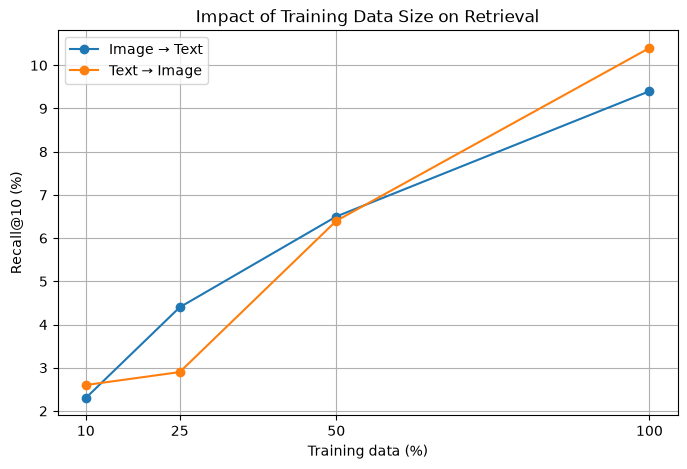

In [181]:
import matplotlib.pyplot as plt

fractions = [10, 25, 50, 100]

i2t_r10 = [
    low_data_test_results["10"]["image_to_text"]["R@10"] * 100,
    low_data_test_results["25"]["image_to_text"]["R@10"] * 100,
    low_data_test_results["50"]["image_to_text"]["R@10"] * 100,
    low_data_test_results["100"]["image_to_text"]["R@10"] * 100
]

t2i_r10 = [
    low_data_test_results["10"]["text_to_image"]["R@10"] * 100,
    low_data_test_results["25"]["text_to_image"]["R@10"] * 100,
    low_data_test_results["50"]["text_to_image"]["R@10"] * 100,
    low_data_test_results["100"]["text_to_image"]["R@10"] * 100
]

plt.figure(figsize=(8, 5))

plt.plot(
    fractions,
    i2t_r10,
    marker="o",
    label="Image → Text"
)

plt.plot(
    fractions,
    t2i_r10,
    marker="o",
    label="Text → Image"
)

plt.xlabel("Training data (%)")
plt.ylabel("Recall@10 (%)")
plt.title("Impact of Training Data Size on Retrieval")

plt.xticks(fractions)
plt.grid(True)
plt.legend()

plt.show()

In [182]:
images = images.to(device)

In [183]:
def apply_noise_randomly(images, sigma, probability):

    batch_size = images.shape[0]

    # une décision aléatoire par image
    corrupt_mask = torch.rand(
        batch_size,
        device=images.device
    ) < probability

    noisy_images = add_gaussian_noise(
        images,
        sigma
    )

    corrupt_mask = corrupt_mask[:, None, None, None]

    output_images = torch.where(
        corrupt_mask,
        noisy_images,
        images
    )

    return output_images

In [184]:
images, captions, masks = next(iter(train_loaders["100"]))

images = images.to(device)

mixed_images = apply_noise_randomly(
    images,
    sigma=0.1,
    probability=0.5
)

print(images.shape)
print(mixed_images.shape)

print(
    "Difference moyenne:",
    torch.abs(images - mixed_images).mean().item()
)

torch.Size([32, 3, 224, 224])
torch.Size([32, 3, 224, 224])
Difference moyenne: 0.03797617182135582


In [185]:
def train_noise_aware(
    model,
    optimizer,
    train_loader,
    val_loader,
    num_epochs,
    patience,
    checkpoint_path,
    sigma=0.1,
    noise_probability=0.5
):

    best_val_loss = float("inf")
    checks_without_improvement = 0
    best_epoch = 0

    train_losses = []
    val_losses = []

    for epoch in range(num_epochs):

        model.train()
        total_loss = 0

        for images, captions, masks in train_loader:

            images = images.to(device)
            captions = captions.to(device)
            masks = masks.to(device)

            # corruption pendant le training uniquement
            images = apply_noise_randomly(
                images,
                sigma=sigma,
                probability=noise_probability
            )

            optimizer.zero_grad()

            logits = model(
                images,
                captions,
                masks
            )

            loss = contrastive_loss(logits)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        train_loss = total_loss / len(train_loader)

        # validation CLEAN
        val_loss = validate_model(
            model,
            val_loader
        )

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        print(
            f"Epoch {epoch + 1} | "
            f"train_loss = {train_loss:.4f} | "
            f"val_loss = {val_loss:.4f}"
        )

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1
            checks_without_improvement = 0

            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "epoch": best_epoch,
                    "val_loss": best_val_loss,
                    "sigma": sigma,
                    "noise_probability": noise_probability
                },
                checkpoint_path
            )

            print("New best robust model saved")

        else:

            checks_without_improvement += 1

            print(
                f"No improvement: "
                f"{checks_without_improvement}/{patience}"
            )

        if checks_without_improvement >= patience:

            print("Early stopping")
            break

    return {
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "train_losses": train_losses,
        "val_losses": val_losses
    }

In [186]:
robust_model, robust_optimizer = create_model_and_optimizer(seed=42)

In [187]:
robust_results = train_noise_aware(
    model=robust_model,
    optimizer=robust_optimizer,
    train_loader=train_loaders["100"],
    val_loader=dev_loader,
    num_epochs=30,
    patience=3,
    checkpoint_path="../models/noise_aware_sigma01.pt",
    sigma=0.1,
    noise_probability=0.5
)

Epoch 1 | train_loss = 3.3831 | val_loss = 3.2842
New best robust model saved
Epoch 2 | train_loss = 3.1986 | val_loss = 3.1824
New best robust model saved
Epoch 3 | train_loss = 3.0951 | val_loss = 3.0941
New best robust model saved
Epoch 4 | train_loss = 3.0085 | val_loss = 3.0242
New best robust model saved
Epoch 5 | train_loss = 2.9651 | val_loss = 3.0045
New best robust model saved
Epoch 6 | train_loss = 2.9021 | val_loss = 3.0694
No improvement: 1/3
Epoch 7 | train_loss = 2.8384 | val_loss = 2.9960
New best robust model saved
Epoch 8 | train_loss = 2.7950 | val_loss = 2.9210
New best robust model saved
Epoch 9 | train_loss = 2.7324 | val_loss = 2.8976
New best robust model saved
Epoch 10 | train_loss = 2.6624 | val_loss = 2.8994
No improvement: 1/3
Epoch 11 | train_loss = 2.5886 | val_loss = 2.8548
New best robust model saved
Epoch 12 | train_loss = 2.5552 | val_loss = 2.8180
New best robust model saved
Epoch 13 | train_loss = 2.4806 | val_loss = 2.8351
No improvement: 1/3
Epoch 

In [188]:
checkpoint_robust = torch.load(
    "../models/noise_aware_sigma01.pt",
    map_location=device
)

robust_model.load_state_dict(
    checkpoint_robust["model_state_dict"]
)

print("Best epoch:", checkpoint_robust["epoch"])
print("Saved val loss:", checkpoint_robust["val_loss"])

robust_val_loss = validate_model(
    robust_model,
    dev_loader
)

print("Reloaded val loss:", robust_val_loss)

Best epoch: 19
Saved val loss: 2.7502685636281967
Reloaded val loss: 2.7502685636281967


In [189]:
robust_clean_results = evaluate_retrieval(
    robust_model,
    test_loader
)

print("Noise-aware model - CLEAN")

print(
    "Image -> Text:",
    robust_clean_results["image_to_text"]
)

print(
    "Text -> Image:",
    robust_clean_results["text_to_image"]
)

Noise-aware model - CLEAN
Image -> Text: {'R@1': 0.020999999716877937, 'R@5': 0.07699999958276749, 'R@10': 0.13600000739097595}
Text -> Image: {'R@1': 0.023000000044703484, 'R@5': 0.08299999684095383, 'R@10': 0.13199999928474426}


In [190]:
def evaluate_gaussian_noise_model(model, sigma):

    torch.manual_seed(42)

    model.eval()

    all_image_embeddings = []
    all_text_embeddings = []

    with torch.no_grad():

        for images, captions, masks in test_loader:

            images = images.to(device)
            captions = captions.to(device)
            masks = masks.to(device)

            images = add_gaussian_noise(
                images,
                sigma
            )

            image_features = model.image_encoder(images)
            image_embeddings = model.projection_image(
                image_features
            )

            text_features = model.text_encoder(
                captions,
                masks
            )

            text_embeddings = model.projection_text(
                text_features
            )

            all_image_embeddings.append(
                image_embeddings.cpu()
            )

            all_text_embeddings.append(
                text_embeddings.cpu()
            )

    image_embeddings = torch.cat(
        all_image_embeddings,
        dim=0
    )

    text_embeddings = torch.cat(
        all_text_embeddings,
        dim=0
    )

    similarities = (
        image_embeddings
        @ text_embeddings.T
    )

    return {
        "image_to_text": {
            "R@1": recall_at_k(similarities, 1),
            "R@5": recall_at_k(similarities, 5),
            "R@10": recall_at_k(similarities, 10)
        },

        "text_to_image": {
            "R@1": recall_at_k(similarities.T, 1),
            "R@5": recall_at_k(similarities.T, 5),
            "R@10": recall_at_k(similarities.T, 10)
        }
    }

In [191]:
robust_noise_results = {}

for sigma in [0.0, 0.05, 0.1, 0.2]:

    results = evaluate_gaussian_noise_model(
        robust_model,
        sigma
    )

    robust_noise_results[str(sigma)] = results

    print(f"\nSigma = {sigma}")
    print("Image -> Text:", results["image_to_text"])
    print("Text -> Image:", results["text_to_image"])


Sigma = 0.0
Image -> Text: {'R@1': 0.020999999716877937, 'R@5': 0.07699999958276749, 'R@10': 0.13600000739097595}
Text -> Image: {'R@1': 0.023000000044703484, 'R@5': 0.08299999684095383, 'R@10': 0.13199999928474426}

Sigma = 0.05
Image -> Text: {'R@1': 0.02199999988079071, 'R@5': 0.07599999755620956, 'R@10': 0.14000000059604645}
Text -> Image: {'R@1': 0.02199999988079071, 'R@5': 0.0860000029206276, 'R@10': 0.12700000405311584}

Sigma = 0.1
Image -> Text: {'R@1': 0.024000000208616257, 'R@5': 0.07699999958276749, 'R@10': 0.12999999523162842}
Text -> Image: {'R@1': 0.02199999988079071, 'R@5': 0.08299999684095383, 'R@10': 0.12300000339746475}

Sigma = 0.2
Image -> Text: {'R@1': 0.014999999664723873, 'R@5': 0.05700000002980232, 'R@10': 0.10199999809265137}
Text -> Image: {'R@1': 0.017999999225139618, 'R@5': 0.07999999821186066, 'R@10': 0.12399999797344208}


In [192]:
clean_model = RobustCLIP(
    feat_dim=256,
    embed_dim=128
).to(device)

checkpoint_clean = torch.load(
    "../models/low_data_100.pt",
    map_location=device
)

clean_model.load_state_dict(
    checkpoint_clean["model_state_dict"]
)

<All keys matched successfully>

In [193]:
clean_noise_results = {}

for sigma in [0.0, 0.05, 0.1, 0.2]:

    results = evaluate_gaussian_noise_model(
        clean_model,
        sigma
    )

    clean_noise_results[str(sigma)] = results

    print(f"\nSigma = {sigma}")
    print("Image -> Text:", results["image_to_text"])
    print("Text -> Image:", results["text_to_image"])


Sigma = 0.0
Image -> Text: {'R@1': 0.013000000268220901, 'R@5': 0.057999998331069946, 'R@10': 0.09399999678134918}
Text -> Image: {'R@1': 0.012000000104308128, 'R@5': 0.05999999865889549, 'R@10': 0.10400000214576721}

Sigma = 0.05
Image -> Text: {'R@1': 0.014999999664723873, 'R@5': 0.052000001072883606, 'R@10': 0.09099999815225601}
Text -> Image: {'R@1': 0.008999999612569809, 'R@5': 0.0689999982714653, 'R@10': 0.0989999994635582}

Sigma = 0.1
Image -> Text: {'R@1': 0.008999999612569809, 'R@5': 0.041999999433755875, 'R@10': 0.07800000160932541}
Text -> Image: {'R@1': 0.00800000037997961, 'R@5': 0.04699999839067459, 'R@10': 0.09200000017881393}

Sigma = 0.2
Image -> Text: {'R@1': 0.009999999776482582, 'R@5': 0.017999999225139618, 'R@10': 0.03799999877810478}
Text -> Image: {'R@1': 0.008999999612569809, 'R@5': 0.03200000151991844, 'R@10': 0.06499999761581421}


Le training avec Gaussian noise améliore fortement la robustesse au bruit et semble également améliorer la généralisation clean dans cette expérience. Cependant, le modèle robuste a bénéficié de davantage d’epochs avant early stopping, donc une ablation supplémentaire est nécessaire pour isoler l’effet de la corruption elle-même.

In [194]:
robust_training_results = {
    "clean_training": clean_noise_results,
    "noise_aware_training": robust_noise_results
}

with open(
    "../results/noise_aware_results.json",
    "w"
) as f:
    json.dump(
        robust_training_results,
        f,
        indent=4
    )

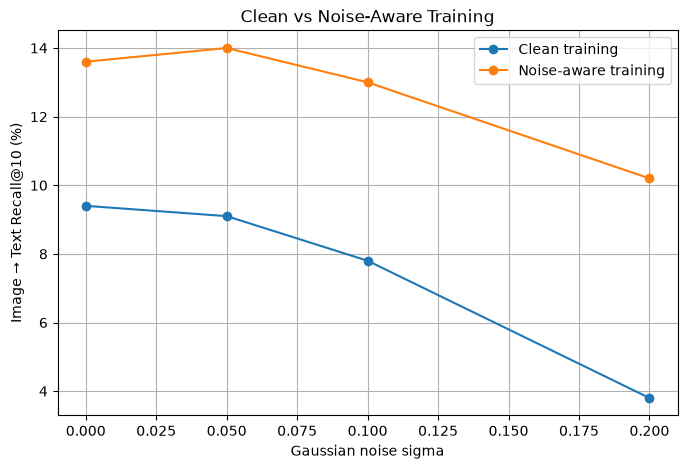

In [195]:
sigmas = [0.0, 0.05, 0.1, 0.2]

clean_i2t = [
    clean_noise_results[str(s)]["image_to_text"]["R@10"] * 100
    for s in sigmas
]

robust_i2t = [
    robust_noise_results[str(s)]["image_to_text"]["R@10"] * 100
    for s in sigmas
]

plt.figure(figsize=(8, 5))

plt.plot(
    sigmas,
    clean_i2t,
    marker="o",
    label="Clean training"
)

plt.plot(
    sigmas,
    robust_i2t,
    marker="o",
    label="Noise-aware training"
)

plt.xlabel("Gaussian noise sigma")
plt.ylabel("Image → Text Recall@10 (%)")
plt.title("Clean vs Noise-Aware Training")

plt.grid(True)
plt.legend()

plt.show()

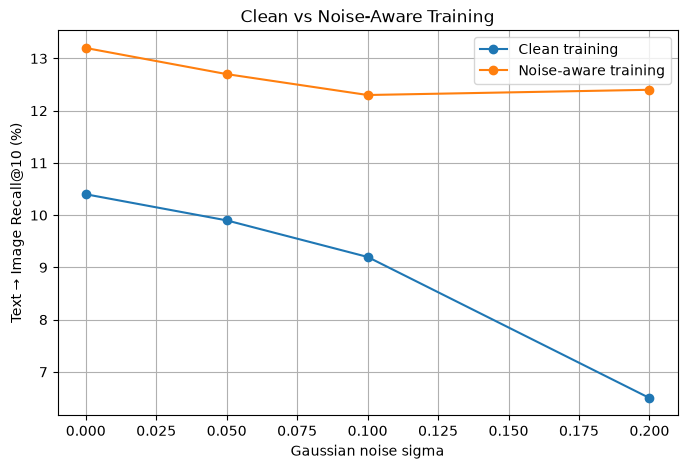

In [196]:
clean_t2i = [
    clean_noise_results[str(s)]["text_to_image"]["R@10"] * 100
    for s in sigmas
]

robust_t2i = [
    robust_noise_results[str(s)]["text_to_image"]["R@10"] * 100
    for s in sigmas
]

plt.figure(figsize=(8, 5))

plt.plot(
    sigmas,
    clean_t2i,
    marker="o",
    label="Clean training"
)

plt.plot(
    sigmas,
    robust_t2i,
    marker="o",
    label="Noise-aware training"
)

plt.xlabel("Gaussian noise sigma")
plt.ylabel("Text → Image Recall@10 (%)")
plt.title("Clean vs Noise-Aware Training")

plt.grid(True)
plt.legend()

plt.show()

In [197]:
def train_fixed_epochs(
    model,
    optimizer,
    train_loader,
    num_epochs
):

    for epoch in range(num_epochs):

        model.train()
        total_loss = 0

        for images, captions, masks in train_loader:

            images = images.to(device)
            captions = captions.to(device)
            masks = masks.to(device)

            optimizer.zero_grad()

            logits = model(
                images,
                captions,
                masks
            )

            loss = contrastive_loss(logits)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        train_loss = total_loss / len(train_loader)

        val_loss = validate_model(
            model,
            dev_loader
        )

        print(
            f"Epoch {epoch + 1} | "
            f"train_loss = {train_loss:.4f} | "
            f"val_loss = {val_loss:.4f}"
        )

In [198]:
clean_19_model, clean_19_optimizer = create_model_and_optimizer(
    seed=42
)

train_fixed_epochs(
    model=clean_19_model,
    optimizer=clean_19_optimizer,
    train_loader=train_loaders["100"],
    num_epochs=19
)

Epoch 1 | train_loss = 3.3800 | val_loss = 3.2767
Epoch 2 | train_loss = 3.1794 | val_loss = 3.1748
Epoch 3 | train_loss = 3.0822 | val_loss = 3.0939
Epoch 4 | train_loss = 3.0029 | val_loss = 3.0125
Epoch 5 | train_loss = 2.9476 | val_loss = 2.9794
Epoch 6 | train_loss = 2.8860 | val_loss = 3.0045
Epoch 7 | train_loss = 2.8190 | val_loss = 2.9079
Epoch 8 | train_loss = 2.7609 | val_loss = 2.8795
Epoch 9 | train_loss = 2.6808 | val_loss = 2.8638
Epoch 10 | train_loss = 2.6147 | val_loss = 2.8264
Epoch 11 | train_loss = 2.5489 | val_loss = 2.7508
Epoch 12 | train_loss = 2.5017 | val_loss = 2.7817
Epoch 13 | train_loss = 2.4219 | val_loss = 2.7738
Epoch 14 | train_loss = 2.3873 | val_loss = 2.8376
Epoch 15 | train_loss = 2.3389 | val_loss = 2.7551
Epoch 16 | train_loss = 2.2712 | val_loss = 2.7127
Epoch 17 | train_loss = 2.2145 | val_loss = 2.7376
Epoch 18 | train_loss = 2.1749 | val_loss = 2.7621
Epoch 19 | train_loss = 2.1007 | val_loss = 2.7355


In [199]:
torch.save(
    {
        "model_state_dict": clean_19_model.state_dict(),
        "optimizer_state_dict": clean_19_optimizer.state_dict(),
        "epoch": 19
    },
    "../models/clean_fixed_19.pt"
)